# MATSim vs. Microcensus (MZMV 2015): Travel Behavior Comparison
**Project focus: Validation of Synthetic Population and Simulated Travel Demand**

This notebook performs a comprehensive comparative analysis between the synthetically generated travel demand (MATSim) and the observed travel diaries from the Swiss Microcensus on Mobility and Transport 2015 (MZMV 2015). 

> **Note on Data Dictionary:** The mapping of Microcensus categorical variables (e.g., transport modes `f51300`, purpose, employment) heavily relies on the official data dictionary: `2017-05-08-Datenbankstruktur_MZMV2015_mit_Geodaten.xlsx`.

---
### TODO: Nødvendige tilpasninger før du kjører koden
* **Stier (Paths):** Sjekk at stiene til `MATSIM_DIR` og `MZ_DIR` stemmer overens med mappestrukturen din.
* **Kolonnenavn for distanse (MZ):** Sjekk om filen `wege.csv` bruker `f51100`, `wdist`, eller `wdist_m` for reiselengde, og oppdater variabelen `MZ_DIST_COL` under.
* **Trafikktellinger (GEH):** Du må bytte ut dummy-dataene i del 6 med de faktiske telledataene fra MATSim-simuleringen og de fysiske tellepunktene i nettverket ditt.



In [482]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path
import shapely.geometry 

# Plotting configuration for high-quality academic outputs
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 150



## 1. Configuration & Data Loading
Setting up the environment and defining parameters. We map the main transport modes from the MZMV2015 (`f51300`) to MATSim terminology to ensure a 1:1 comparison.


In [483]:
# ==========================================
# CONFIGURATION
# ==========================================
MATSIM_DIR = Path('simulation_filter')
MZ_DIR = Path('microcensus_filter')

FOCUS_MODE = 'bike' # The specific mode evaluated in depth for this project

# Distance bins (in meters)
BINS = [0, 2000, 5000, 10000, 20000, 50000, np.inf]
BIN_LABELS = ['0-2 km', '2-5 km', '5-10 km', '10-20 km', '20-50 km', '50+ km']

# Socio-demographics to analyze (Ensuring at least 2 as required)
SOCIO_DEMOS = ['age_group', 'sex_group', 'employment_group']

# Mapping f51300 (Hauptverkehrsmittel) to MATSim modes 
# Reference: 2017-05-08-Datenbankstruktur_MZMV2015_mit_Geodaten.xlsx
MZ_MODE_MAP = {
    1: 'other',       # Flugzeug
    2: 'pt',       # bahn
    3: 'pt',      # postauto
    4: 'other',        # schiff
    5: 'pt',        # tram
    6: 'pt',        # bus
    7: 'pt',         # sonstiger oec
    8: 'other',         # reisecar
    9: 'car',         # auto
    10: 'other',     # lastwagen
    11: 'car_passenger',     # Taxi
    12: 'car',      # motorrad
    13: 'moped',      # mofa
    14: 'bike',      # velo
    15: 'walk',      # fuss
    16: 'other',      # ahrzeugähnliche Geräte
    17: 'other',      # anderes, weiss nicht, keine Antwort
    
}

# TODOk: Sjekk hva distansekolonnen for wege (turer) heter i ditt Microcensus-uttrekk.
MZ_DIST_COL = 'w_rdist' # Bytt til 'f51100' hvis wdist_m ikke finnes i wege.csv

### Loading and Merging Datasets
We merge the trip datasets with the person datasets to inherit sociodemographic attributes (age, sex, employment) and, crucially for the Microcensus, the expansion weights (`WP`).


In [484]:
def load_and_prepare_data():
    try:
        # Load MATSim Data
        ms_persons = pd.read_csv(MATSIM_DIR / 'simulation_persons.csv', keep_default_na=False)
        ms_trips = pd.read_csv(MATSIM_DIR / 'simulation_trips.csv', keep_default_na=False)
        
        # Load Microcensus Data
        mz_persons = pd.read_csv(MZ_DIR / 'microcensus_ne_weekday_persons.csv', keep_default_na=False)
        mz_trips = pd.read_csv(MZ_DIR / 'microcensus_ne_weekday_trips.csv', keep_default_na=False)
        
        # Merge Person demographics into Trips
        # MATSim uses 'person', MZ uses 'HHNR' (Target persons in households)
        ms_merged = ms_trips.merge(ms_persons[['person', 'carAvail', 'bikeAvail', "municipalityType", "ovgk"]], on='person', how='left')
        
        # In MZ, we need the person weights (WP) and household coordinates (hh_W_X_CH1903)
        mz_demo_cols = ['HHNR', 'alter', 'gesl', 'erwerb', 'hh_W_X_CH1903', 'hh_W_Y_CH1903', "AMSTAT", "f42100e", "f42100a", "hh_W_staedt_char_2012", "hh_W_OeV_KLASSE"]
        # TOD OK: Sjekk at disse demografiske kolonnene ('alter', 'gesl', 'erwerb') finnes i person-filen din. Endre navn hvis nødvendig.
        available_mz_cols = [c for c in mz_demo_cols if c in mz_persons.columns]
        
        mz_merged = mz_trips.merge(mz_persons[available_mz_cols], on='HHNR', how='left')
        
        # Apply Mode Mapping to MZ
        # TODO: Sjekk at wmittel finnes i mz_trips (wege.csv). Hvis ikke, bruk riktig kolonne for hovedtransportmiddel.
        if 'wmittel' in mz_merged.columns:
            mz_merged['mode'] = pd.to_numeric(mz_merged['wmittel'], errors='coerce').map(MZ_MODE_MAP).fillna('other')
        else:
            print("WARNING: 'wmittel' missing from MZ trips. Mode mapping bypassed.")
            mz_merged['mode'] = 'unknown'
            
        # Filter MATSim for age >= 6 (comparable universe)
        ms_merged = ms_merged[ms_merged['comparison_age_eligible'] == True]
        
        return ms_merged, mz_merged
    except FileNotFoundError as e:
        print(f"File not found. Please ensure the preprocessing scripts have been executed. Error: {e}")
        return pd.DataFrame(), pd.DataFrame()

ms_df, mz_df = load_and_prepare_data()
# Quick validation print
if not ms_df.empty and not mz_df.empty:
    print(f"Loaded MATSim Trips: {len(ms_df):,}")
    print(f"Loaded Microcensus Trips: {len(mz_df):,}")
    print(f"MATSim Columns: {ms_df.columns.tolist()}")
    print(f"Microcensus Columns: {mz_df.columns.tolist()}")



Loaded MATSim Trips: 62,485
Loaded Microcensus Trips: 7,835
MATSim Columns: ['person', 'trip_index', 'origin_activity_index', 'destination_activity_index', 'origin_type', 'destination_type', 'origin_x', 'origin_y', 'destination_x', 'destination_y', 'leg_count', 'modes', 'routing_modes', 'route_distance_m', 'has_boundary_proxy', 'age_group', 'sex_group', 'employment_group', 'comparison_age_eligible', 'sample_weight', 'carAvail', 'bikeAvail', 'municipalityType', 'ovgk']
Microcensus Columns: ['HHNR', 'WP', 'AUSNR', 'WEGNR', 'DMOD', 'f51100', 'f51400', 'f51100time', 'f51400time', 'pseudo', 'W_X', 'W_Y', 'W_X_CH1903', 'W_Y_CH1903', 'W_QAL', 'W_BFS', 'W_PLZ', 'W_Ort', 'W_Str', 'W_hnr', 'W_SPRACHE', 'W_REGION', 'W_KANTON', 'W_AGGLO2000', 'W_AGGLO_GROESSE2000', 'W_STRUKTUR_2000', 'W_STRUKTUR_AGG_2000', 'w_struktur_bfs9_2000', 'W_AGGLO2012', 'W_AGGLO_GROESSE2012', 'W_staedt_char_2012', 'W_stat_stadt_2012', 'W_ISO_Staedte_MIV', 'W_ISO_Staedte_OeV', 'W_OeV_KLASSE', 'W_DEGURBA', 'S_X', 'S_Y', 'S_X

/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_12658/596721909.py:25: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mz_merged['mode'] = pd.to_numeric(mz_merged['wmittel'], errors='coerce').map(MZ_MODE_MAP).fillna('other')


## 2. Aggregated Mode-Share Comparison
This section compares the total modal split. The MATSim data represents the synthetic population directly, while the Microcensus data is weighted using the `WP` person weights to ensure representativeness at the cantonal level.


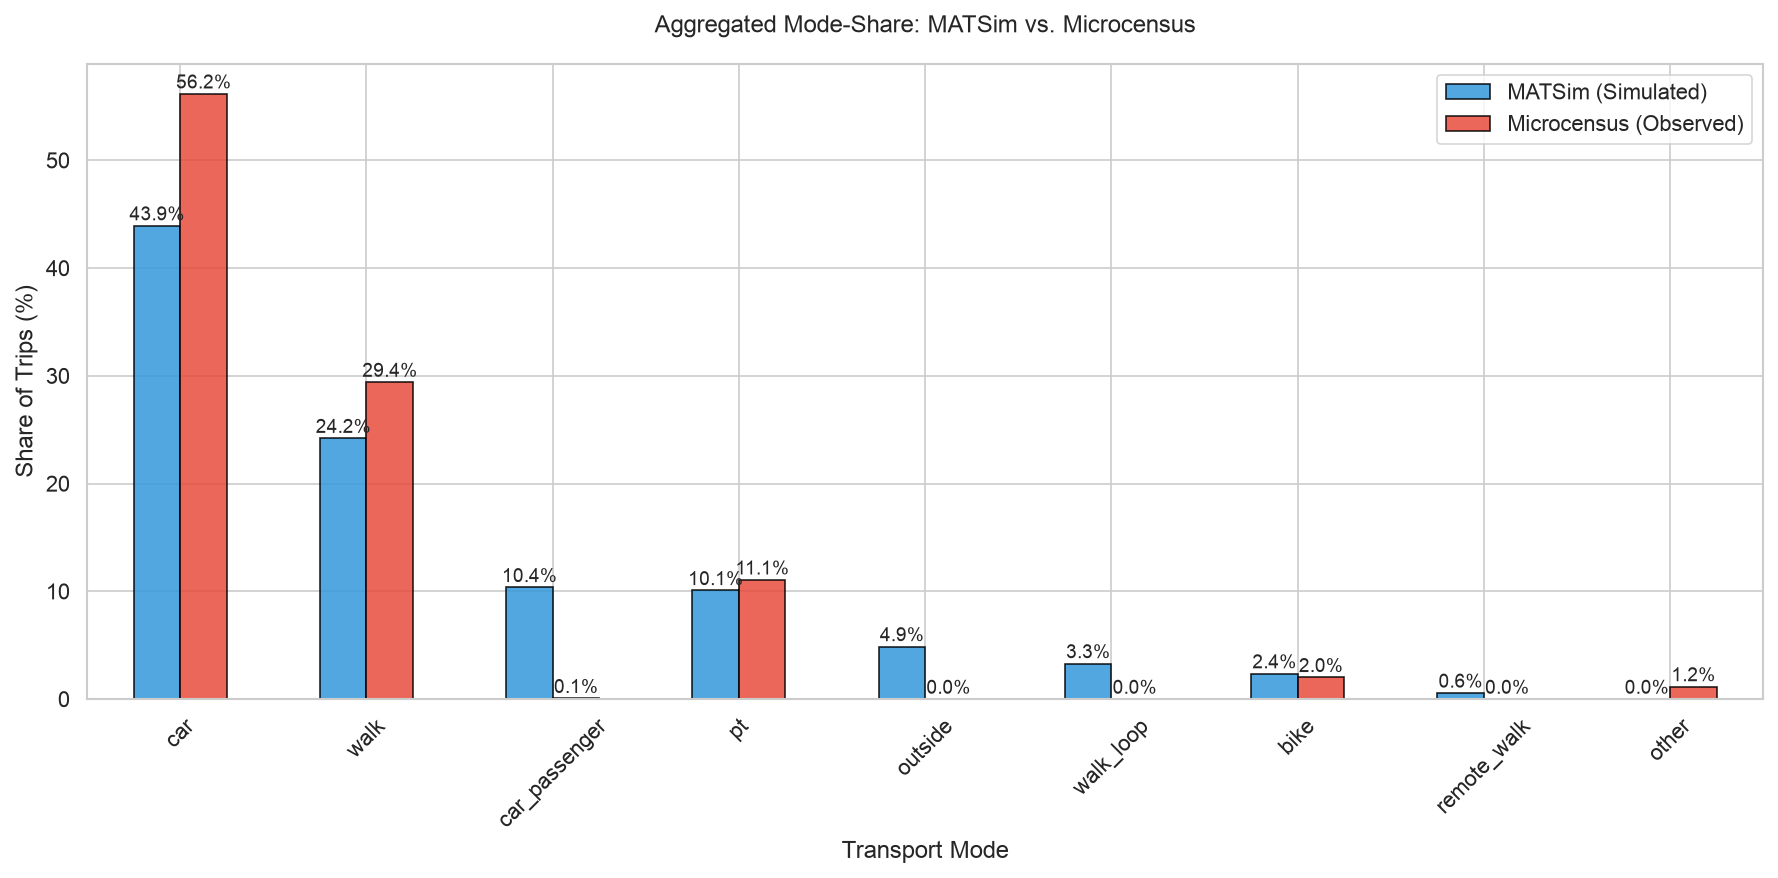

In [485]:
def check_aggregated_modeshare(ms, mz):
    if ms.empty or mz.empty: return
    
    # MATSim: Unweighted counts (or weight=1)
    ms_share = ms['routing_modes'].value_counts(normalize=True) * 100
    ms_share.name = 'MATSim (Simulated)'
    
    # Microcensus: Weighted by WP
    mz_weighted_counts = mz.groupby('mode')['WP'].sum()
    mz_share = (mz_weighted_counts / mz_weighted_counts.sum()) * 100
    mz_share.name = 'Microcensus (Observed)'
    
    # Align and plot
    df_share = pd.concat([ms_share, mz_share], axis=1).fillna(0)
    
    # Filter out near-zero categories for a cleaner plot
    df_share = df_share[(df_share > 0.5).any(axis=1)]
    
    ax = df_share.plot(kind='bar', color=['#3498db', '#e74c3c'], edgecolor='black', alpha=0.85)
    plt.title('Aggregated Mode-Share: MATSim vs. Microcensus', pad=15)
    plt.ylabel('Share of Trips (%)')
    plt.xlabel('Transport Mode')
    plt.xticks(rotation=45)
    
    # Annotate bars
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)
        
    plt.legend()
    plt.tight_layout()
    plt.show()

check_aggregated_modeshare(ms_df, mz_df)



## 3. Mode-Share by Distance Bins
Travel behavior is highly dependent on trip distance. We aggregate trips into discrete spatial bins to verify whether the simulation captures the correct distance-decay behavior per mode (e.g., walking dominates short trips, cars/PT dominate long trips).


/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_12658/1507307998.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mz['dist_bin'] = pd.cut(pd.to_numeric(mz[MZ_DIST_COL] * 1000, errors='coerce'), bins=BINS, labels=BIN_LABELS)


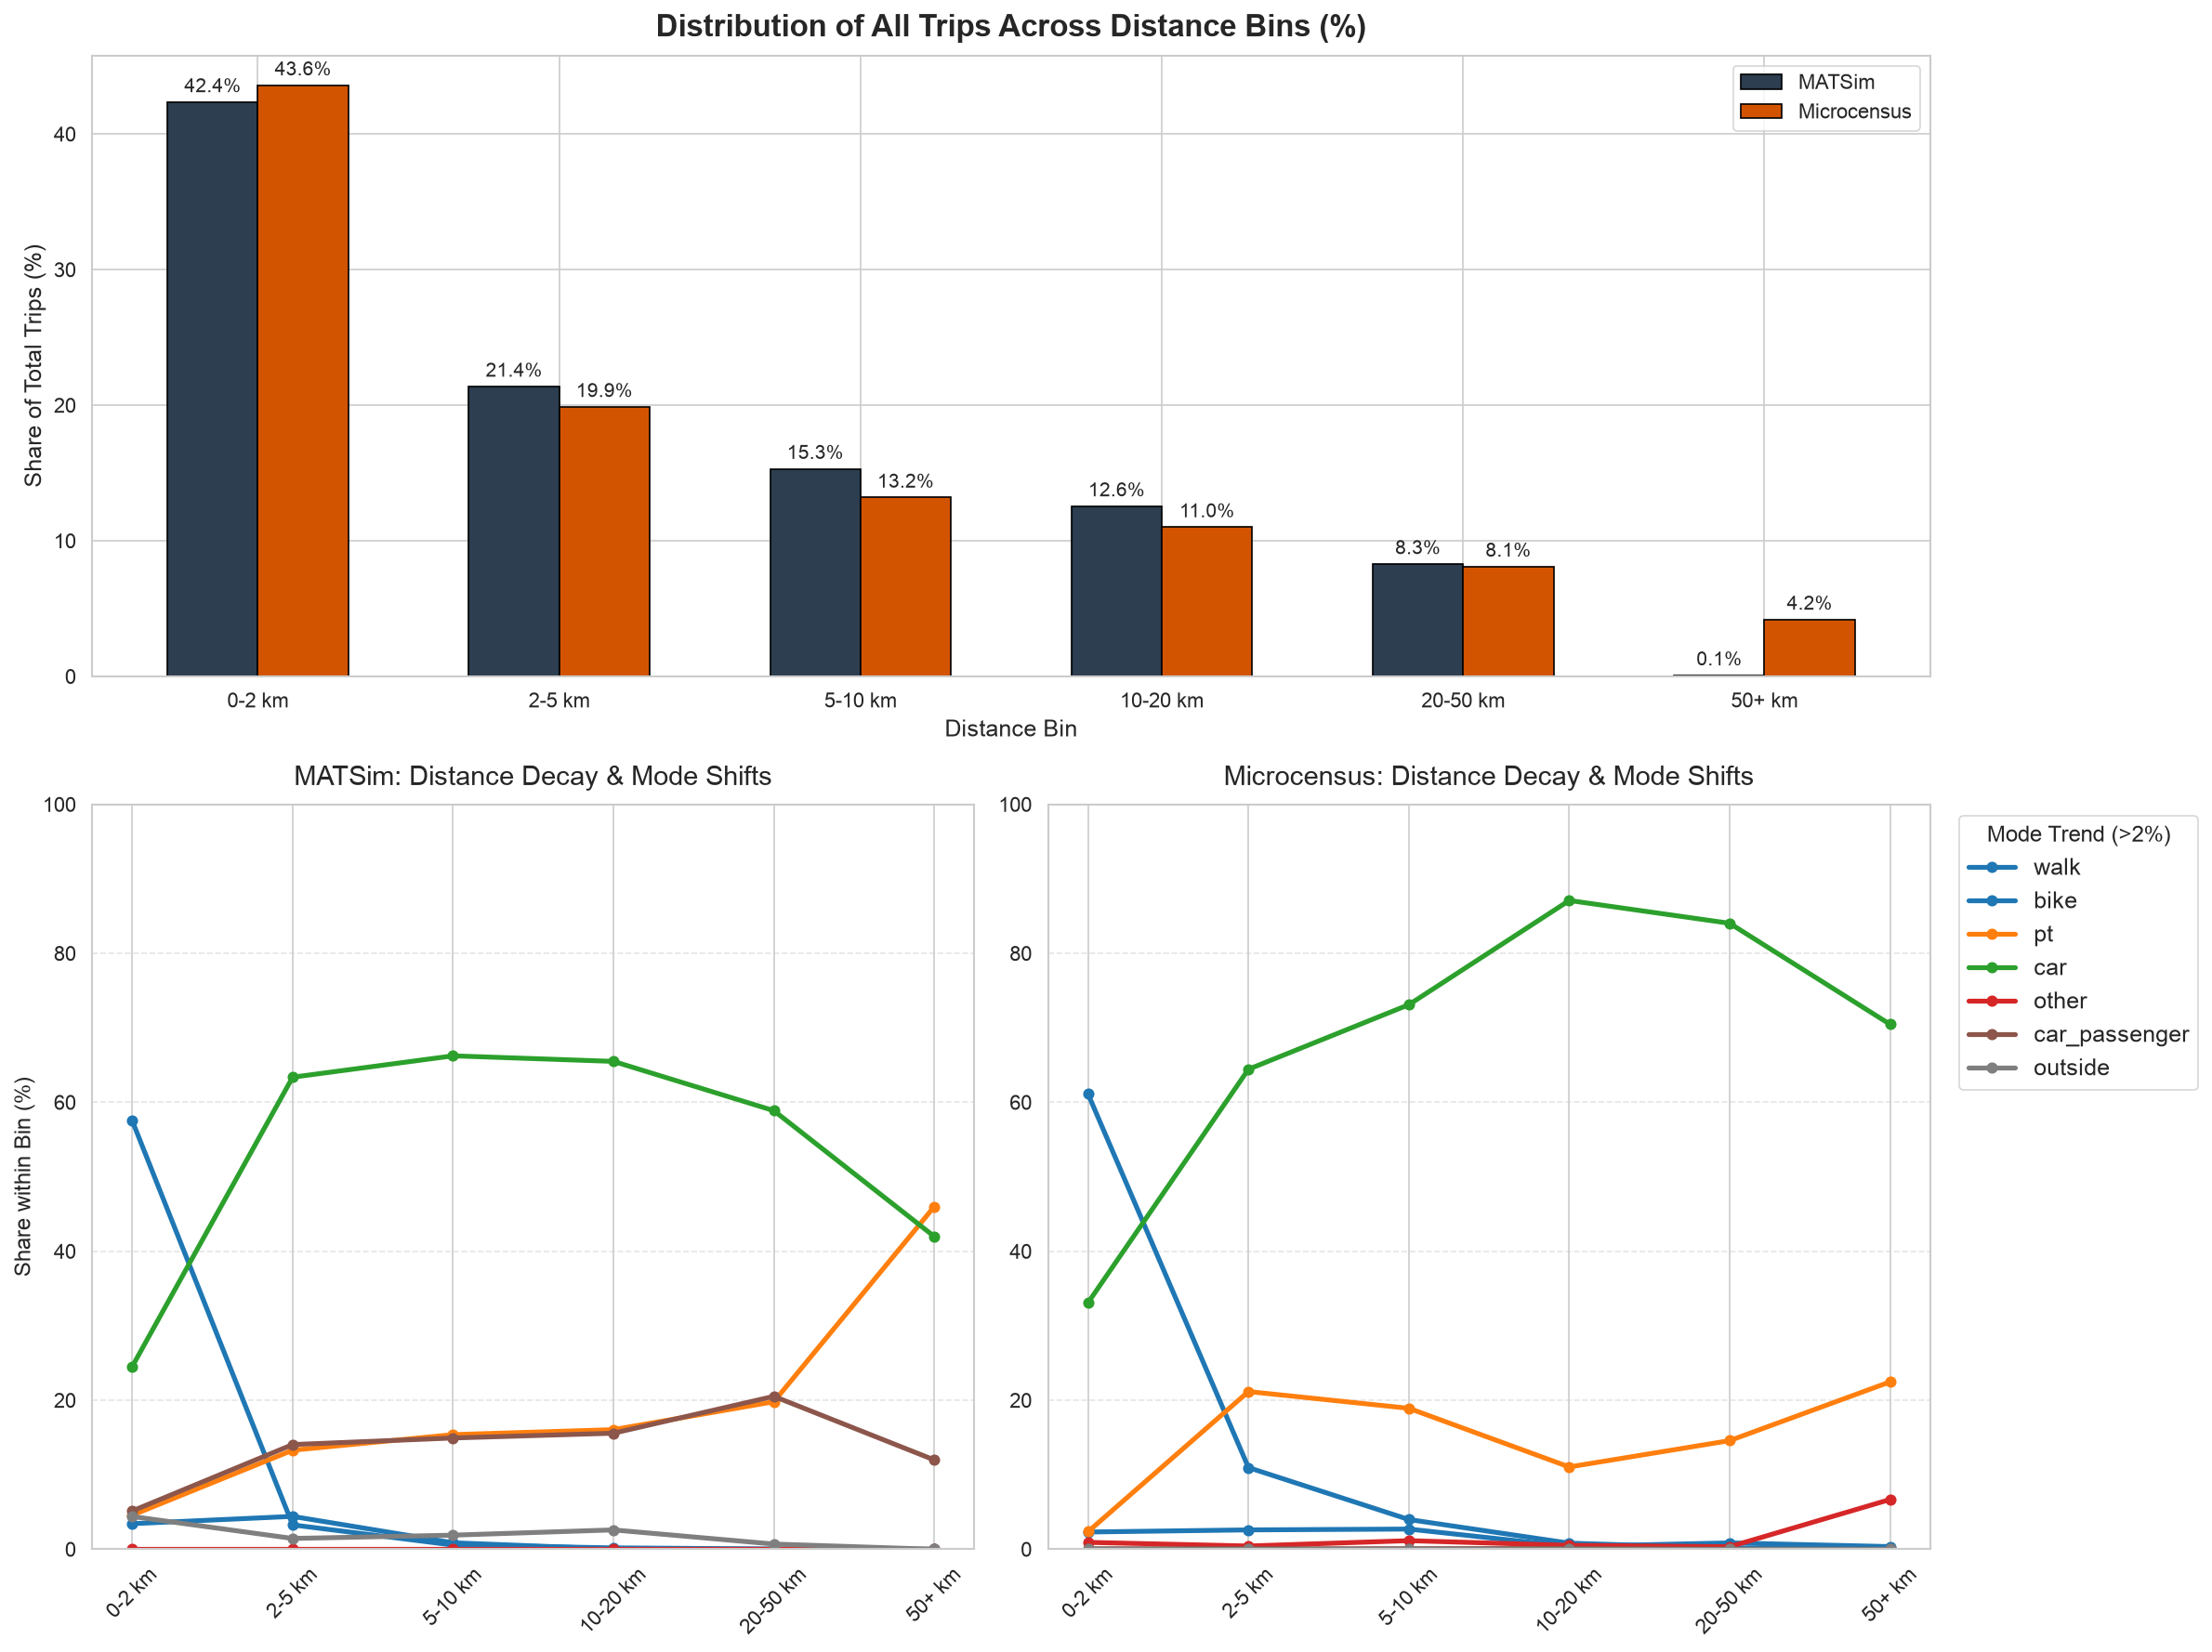

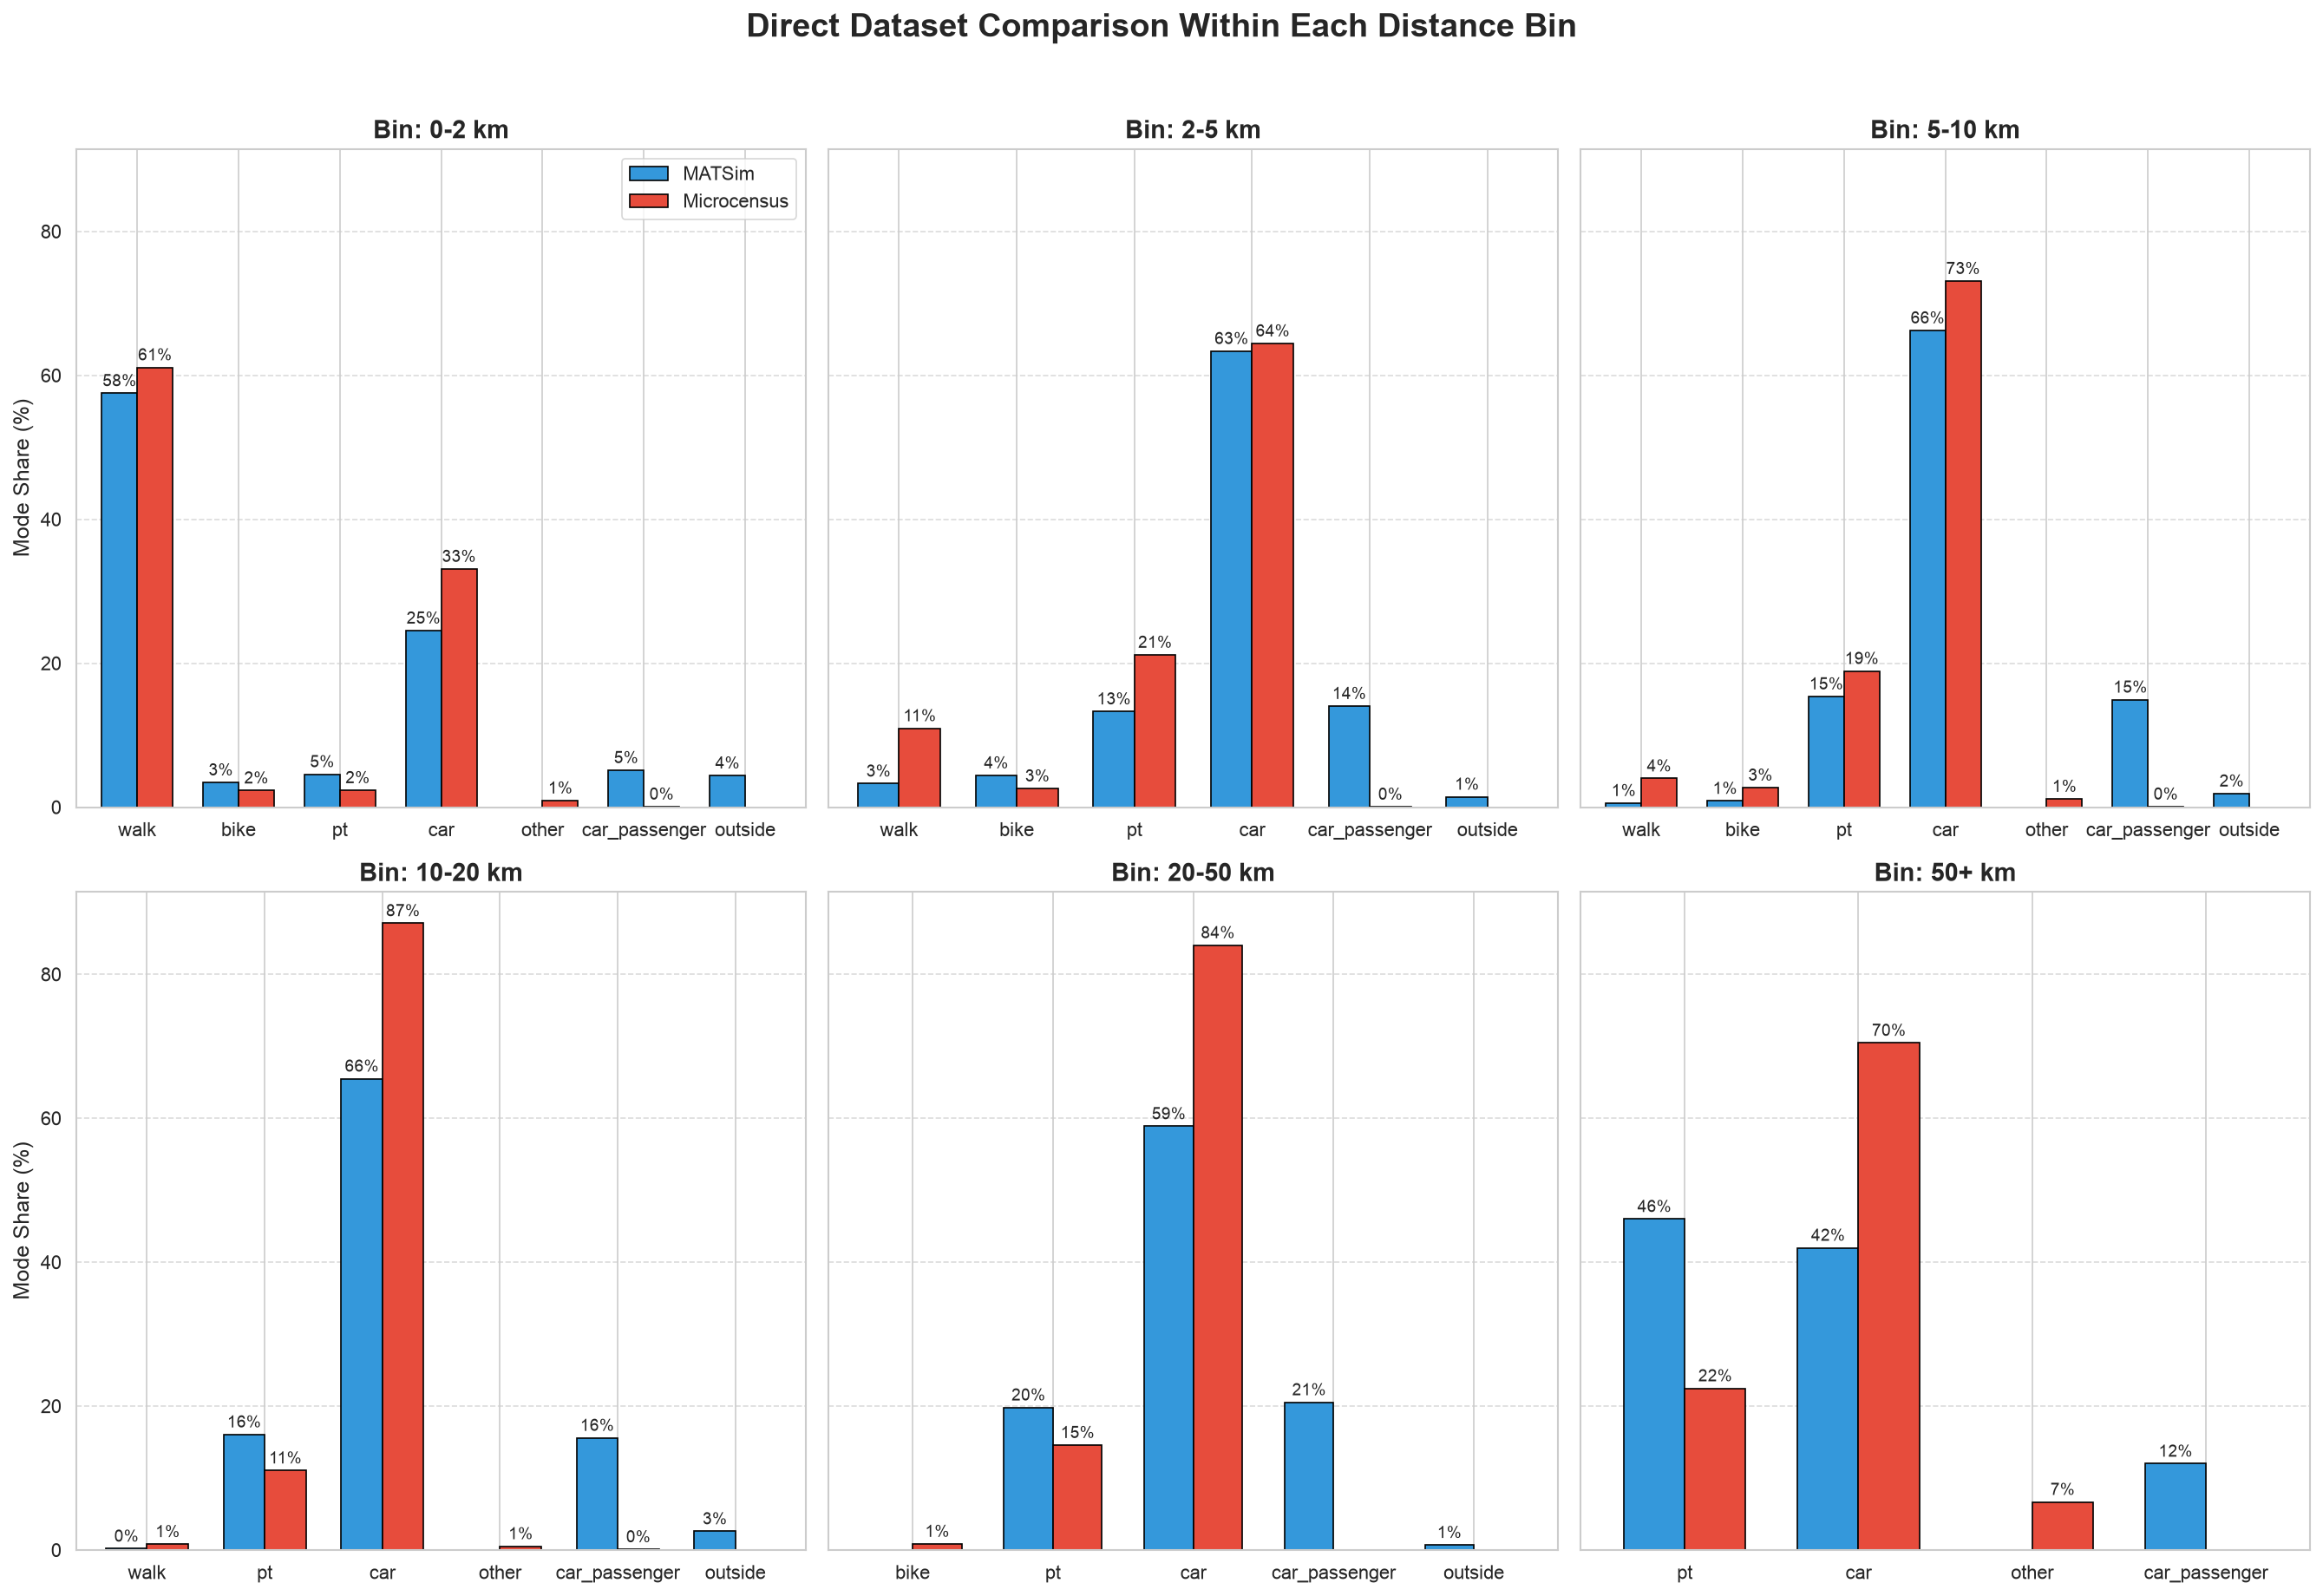

In [486]:
# ==========================================
# 2. MODE-SHARE BY DISTANCE BINS (COMPREHENSIVE)
# ==========================================
def check_modeshare_distance_bins(ms, mz):
    if ms.empty or mz.empty: return
    
    # 1. Map distances to Bins
    ms['dist_bin'] = pd.cut(ms['route_distance_m'], bins=BINS, labels=BIN_LABELS)
    
    if MZ_DIST_COL in mz.columns:
        # Konverterer MZ-distanse til meter. Hvis den allerede er i meter, fjern "* 1000"
        mz['dist_bin'] = pd.cut(pd.to_numeric(mz[MZ_DIST_COL] * 1000, errors='coerce'), bins=BINS, labels=BIN_LABELS)
    else:
        print(f"Missing MZ distance column: {MZ_DIST_COL}")
        return

    mode_col_ms = 'routing_modes'

    # 2. Calculate Trip Volumes per Bin (Gjort om til prosent / relative tall)
    ms_vol = ms.groupby('dist_bin', observed=False).size()
    ms_vol_pct = (ms_vol / ms_vol.sum()) * 100
    
    mz_vol_weighted = mz.groupby('dist_bin', observed=False)['WP'].sum()
    mz_vol_pct = (mz_vol_weighted / mz_vol_weighted.sum()) * 100
    
    vol_compare_df = pd.DataFrame({'MATSim': ms_vol_pct, 'Microcensus': mz_vol_pct})
    
    # 3. Calculate Mode Shares per Bin
    ms_bin = ms.groupby(['dist_bin', mode_col_ms], observed=False).size().unstack(fill_value=0)
    ms_bin_pct = ms_bin.div(ms_bin.sum(axis=1), axis=0) * 100
    
    mz_bin = mz.groupby(['dist_bin', 'mode'], observed=False)['WP'].sum().unstack(fill_value=0)
    mz_bin_pct = mz_bin.div(mz_bin.sum(axis=1), axis=0) * 100
    
    # --- DEFINER ØNSKET REKKEFØLGE FOR TRANSPORTMIDLENE ---
    custom_order = ['walk', 'bike', 'pt', 'car', 'moped', 'other', 'unknown']
    
    # Hent alle unike moduser som finnes i datasettene
    all_present_modes = sorted(list(set(ms_bin_pct.columns) | set(mz_bin_pct.columns)))
    
    # Sorter dem slik du ba om, med de resterende lagt til på slutten
    common_modes = [m for m in custom_order if m in all_present_modes] + \
                   [m for m in all_present_modes if m not in custom_order]
    
    ms_bin_pct = ms_bin_pct.reindex(columns=common_modes, fill_value=0)
    mz_bin_pct = mz_bin_pct.reindex(columns=common_modes, fill_value=0)
    
    # Lagre fargene i et dictionary slik at de forblir konsistente selv med ny rekkefølge
    cmap = plt.get_cmap('tab10')
    mode_colors = {mode: cmap(i / len(common_modes) if len(common_modes) > 0 else 0) for i, mode in enumerate(common_modes)}

    # =========================================================
    # FIGUR 1: OVERORDNET TREND OG DISTRIBUSJON
    # =========================================================
    fig = plt.figure(figsize=(16, 12))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2]) # Fjernet midterste rad
    
    # --- RAD 1: Relativt tur-volum (Én felles graf som strekker seg over begge kolonner) ---
    ax_vol = fig.add_subplot(gs[0, :])
    vol_compare_df.plot(kind='bar', ax=ax_vol, color=['#2c3e50', '#d35400'], edgecolor='black', width=0.6)
    ax_vol.set_title('Distribution of All Trips Across Distance Bins (%)', fontsize=16, pad=10, weight='bold')
    ax_vol.set_ylabel('Share of Total Trips (%)', fontsize=12)
    ax_vol.set_xlabel('Distance Bin', fontsize=12)
    ax_vol.tick_params(axis='x', rotation=0)
    
    for p in ax_vol.patches:
        height = p.get_height()
        if height > 0:
            ax_vol.annotate(f"{height:.1f}%", 
                            (p.get_x() + p.get_width() / 2., height), 
                            ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

    # --- RAD 2: Trendlinjer ---
    ax_trend_ms = fig.add_subplot(gs[1, 0])
    ax_trend_mz = fig.add_subplot(gs[1, 1], sharey=ax_trend_ms)
    
    for mode in common_modes:
        color = mode_colors[mode]
        # Sjekk om modusen har over 2% share i *minst ett* av datasettene
        if ms_bin_pct[mode].max() > 2 or mz_bin_pct[mode].max() > 2:
            ax_trend_ms.plot(ms_bin_pct.index, ms_bin_pct[mode], marker='o', linewidth=2.5, color=color, label=mode)
            ax_trend_mz.plot(mz_bin_pct.index, mz_bin_pct[mode], marker='o', linewidth=2.5, color=color, label=mode)

    ax_trend_ms.set_title('MATSim: Distance Decay & Mode Shifts', fontsize=14, pad=10)
    ax_trend_ms.set_ylabel('Share within Bin (%)')
    ax_trend_mz.set_title('Microcensus: Distance Decay & Mode Shifts', fontsize=14, pad=10)

    for ax in [ax_trend_ms, ax_trend_mz]:
        ax.tick_params(axis='x', rotation=45)
        ax.grid(axis='y', linestyle='--', alpha=0.5)
        ax.set_ylim(0, 100)

    ax_trend_mz.legend(title="Mode Trend (>2%)", bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=12)
    
    plt.tight_layout()
    plt.show()

    # =========================================================
    # FIGUR 2: DETALJERT SAMMENLIGNING PER AVSTANDS-BIN
    # =========================================================
    num_bins = len(BIN_LABELS)
    cols = 3
    rows = (num_bins + cols - 1) // cols
    
    fig2, axes2 = plt.subplots(rows, cols, figsize=(18, 6 * rows), sharey=True)
    axes2 = axes2.flatten()
    
    for i, bin_label in enumerate(BIN_LABELS):
        if bin_label in ms_bin_pct.index and bin_label in mz_bin_pct.index:
            # Hent data for akkurat denne bin-en
            df_bin = pd.DataFrame({
                'MATSim': ms_bin_pct.loc[bin_label],
                'Microcensus': mz_bin_pct.loc[bin_label]
            })
            
            # Reindekser slik at transportmidlene vises i den egendefinerte rekkefølgen
            df_bin = df_bin.loc[common_modes]
            
            # Fjern transportmidler som ikke har noe trafikk i denne bin-en i noen av datasettene
            df_bin = df_bin[(df_bin > 0.5).any(axis=1)]
            
            # Plott grupperte søyler
            df_bin.plot(kind='bar', ax=axes2[i], color=['#3498db', '#e74c3c'], edgecolor='black', width=0.7)
            
            axes2[i].set_title(f'Bin: {bin_label}', fontsize=14, weight='bold')
            if i % cols == 0:
                axes2[i].set_ylabel('Mode Share (%)', fontsize=12)
            axes2[i].set_xlabel('')
            axes2[i].tick_params(axis='x', rotation=0)
            
            axes2[i].grid(axis='y', linestyle='--', alpha=0.7)
            
            for p in axes2[i].patches:
                height = p.get_height()
                if height > 0:
                    axes2[i].annotate(f"{height:.0f}%", 
                                     (p.get_x() + p.get_width() / 2., height), 
                                     ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')
                    
            if i == 0:
                axes2[i].legend(loc='upper right')
            else:
                axes2[i].legend_.remove()
                
    for j in range(i + 1, len(axes2)):
        fig2.delaxes(axes2[j])

    fig2.suptitle('Direct Dataset Comparison Within Each Distance Bin', fontsize=18, weight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

check_modeshare_distance_bins(ms_df, mz_df)

## 4. Mode-Share by Socio-Demographics
Validating modal choices against sociodemographic profiles ensures that the synthetic population and discrete choice models behave correctly for different population segments (e.g., assessing mobility constraints for non-employed persons or different age groups).

> **TODO (Norwegian):** For å få dette til å fungere for MZ, må du lage en "mapping" som grupperer kolonnene `alter`, `gesl` (kjønn) og `erwerb` (sysselsetting) i de samme kategoriene som du finner i MATSim-filen (`age_group`, `sex_group`, `employment_group`). Bytt ut kolonnenavnene under hvis nødvendig.


/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_12658/3877102625.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mz['age_group'] = pd.cut(pd.to_numeric(mz['alter'], errors='coerce'),
/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_12658/3877102625.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mz['sex_group'] = pd.to_numeric(mz['gesl'], errors='coerce').map({1: 'male', 2: 'female'}).fillna('unknown')
/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_12658/3877102625.py:33: PerformanceWar

carAvail
always    43454
never     19031
Name: count, dtype: int64
bikeAvail
always    43198
never     19287
Name: count, dtype: int64
municipalityType
urbancore      28706
suburban       18093
urban          11743
rural           3922
crossborder       21
Name: count, dtype: int64
ovgk
A              22239
B              13812
D              12472
C               8374
None            5567
crossborder       21
Name: count, dtype: int64


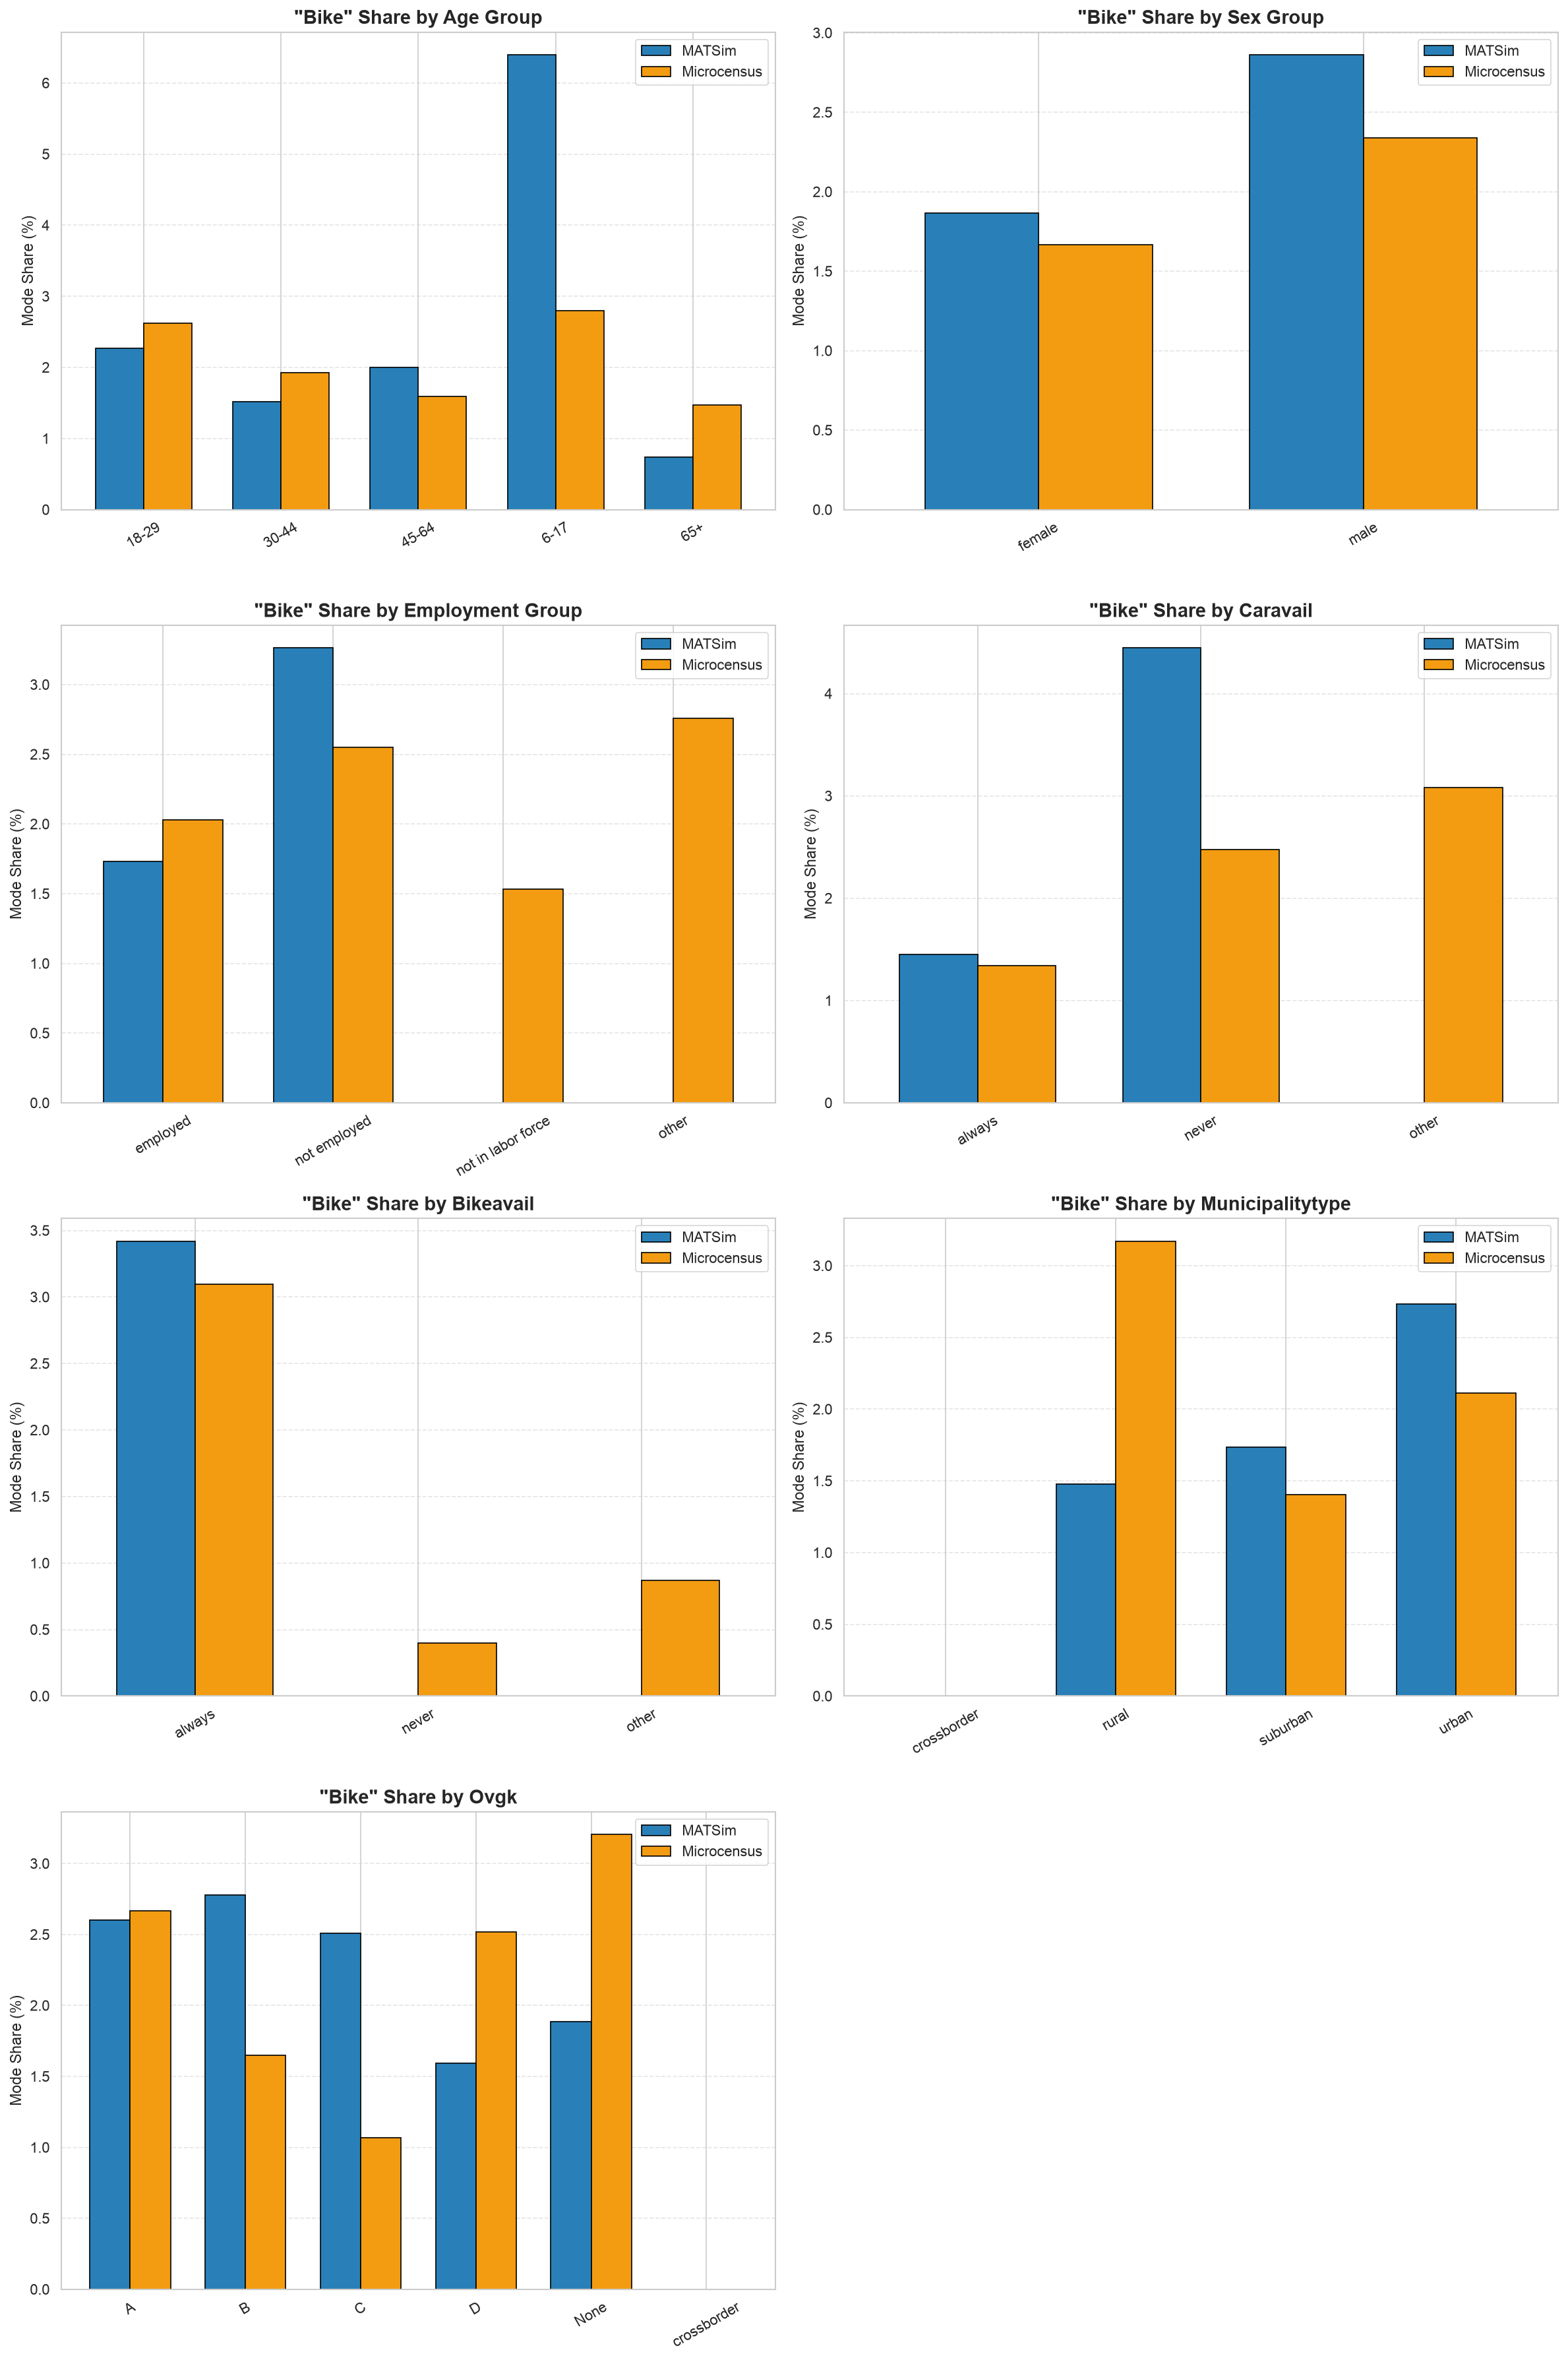

In [487]:
# ==========================================
# 3. MODE-SHARE BY SOCIO-DEMOGRAPHICS (HARMONIZED & EXPANDED)
# ==========================================
# Why age group looked wrong previously:
# 1. Bin edges for pd.cut: [0, 6, 18, 30, 45, 65, 120] with right=False (default) creates bins:
#    - [0, 6) -> 0 to 5.99 (Label '0-5')
#    - [6, 18) -> 6 to 17.99 (Label '6-17')
#    If the comparison universe for MATSim was filtered for age >= 6 elsewhere, but MZ still contained 
#    ages < 6 (or vice versa), or if labels didn't align with the harmonization table ('6-17, 18-29, 30-44, 45-64, 65+'),
#    the categories become misaligned or include uncompared infants (0-5).
# 2. Furthermore, matching requires exact harmonization bins across both datasets as specified in the table:
#    Bins should strictly be [6, 18, 30, 45, 65, 120] with labels ['6-17', '18-29', '30-44', '45-64', '65+'].

def check_socio_demographics(ms, mz, focus=FOCUS_MODE):
    if ms.empty or mz.empty: return
    
    # --- HARMONIZATION FOR MICROZENSUS ---
    # 1. Age (Target: 6-17, 18-29, 30-44, 45-64, 65+)
    if 'alter' in mz.columns:
        mz['age_group'] = pd.cut(pd.to_numeric(mz['alter'], errors='coerce'), 
                                 bins=[6, 18, 30, 45, 65, 120], 
                                 labels=['6-17', '18-29', '30-44', '45-64', '65+'], 
                                 right=False)
        
        ms["age_group"] = ms["age_group"].str.replace("–", "-")
    
    # 2. Sex (Target: Male, Female, Unknown)
    if 'gesl' in mz.columns:
        mz['sex_group'] = pd.to_numeric(mz['gesl'], errors='coerce').map({1: 'male', 2: 'female'}).fillna('unknown')
        
    # 3. Employment (Target: Employed, Not employed based on AMSTAT / ESTATUS fallback)
    if 'AMSTAT' in mz.columns:
        mz['employment_group'] = pd.to_numeric(mz['AMSTAT'], errors='coerce').map(
                   lambda x: 
                   'employed' if x == 1 else 
                   ('not employed' if x == 2 else 
                    ('not in labor force' if x == 3 
                     else 'other'))
        ).fillna('unknown')
       

    # 4. Car Availability (Target: Source categories retained)
    print(ms['carAvail'].value_counts())
    print(ms['bikeAvail'].value_counts())
    print(ms['municipalityType'].value_counts())
    print(ms['ovgk'].value_counts())
    if 'f42100e' in mz.columns:
        mz['carAvail'] = pd.to_numeric(mz['f42100e'], errors='coerce').map(
                   lambda x: 
                   'always' if x == 1 else 
                   ('never' if x == 3 else
                     'other')).fillna('unknown')

    # 5. Bicycle Availability (Target: Source categories retained)
    if 'f42100a' in mz.columns:
        mz['bikeAvail'] = pd.to_numeric(mz['f42100a'], errors='coerce').map(
                   lambda x: 
                   'always' if x == 1 else 
                   ('never' if x == 3 else
                     'other')).fillna('unknown')

    # 6. Urbanization (Target: Urban, Suburban, Rural, Unknown)
    if 'hh_W_staedt_char_2012' in mz.columns:
        mz['municipalityType'] = pd.to_numeric(mz['hh_W_staedt_char_2012'], errors='coerce').map(
            {0:'rural',1:'urban',2:'urban',3:'urban',4:'suburban',5:'suburban',6:'rural'}
        ).fillna('Unknown')
        ms['municipalityType'] = ms['municipalityType'].replace({"urbancore": "urban"})

    # 7. Public Transport Class (Target: A, B, C, D, No class, Unknown)
    if 'hh_W_OeV_KLASSE' in mz.columns:
        mz['ovgk'] = pd.to_numeric(mz['hh_W_OeV_KLASSE'], errors='coerce').map(
            {1: 'A', 2: 'B', 3: 'C', 4: 'D', 5: 'None'}
        ).fillna('Unknown')


    # --- FEATURES TO PLOT (All 7 harmonized characteristics) ---
    features_to_plot = [
        'age_group', 'sex_group', 'employment_group', 
        'carAvail', 'bikeAvail', 'municipalityType', 'ovgk'
    ]
    
    # Filter only features present in both datasets
    active_features = [f for f in features_to_plot if f in ms.columns and f in mz.columns]
    
    if not active_features:
        print("No harmonized socio-demographic features found in both datasets.")
        return

    # Create subplots grid (e.g., 2 columns layout)
    cols = 2
    rows = (len(active_features) + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(16, 6 * rows))
    axes = axes.flatten()
    
    for i, feature in enumerate(active_features):
        ax = axes[i]
        
        # Calc share of FOCUS_MODE per demographic group
        ms_tot = ms.groupby(feature, observed=False).size()
        ms_mod = ms[ms['routing_modes'] == focus].groupby(feature, observed=False).size()
        ms_pct = (ms_mod / ms_tot * 100).fillna(0)
        
        mz_tot = mz.groupby(feature, observed=False)['WP'].sum()
        mz_mod = mz[mz['mode'] == focus].groupby(feature, observed=False)['WP'].sum()
        mz_pct = (mz_mod / mz_tot * 100).fillna(0)
        
        df_comp = pd.DataFrame({'MATSim': ms_pct, 'Microcensus': mz_pct}).fillna(0)
        
        df_comp.plot(kind='bar', ax=ax, color=['#2980b9', '#f39c12'], edgecolor='black', width=0.7)
        ax.set_title(f'"{focus.capitalize()}" Share by {feature.replace("_", " ").title()}', fontsize=14, weight='bold')
        ax.set_ylabel('Mode Share (%)', fontsize=11)
        ax.set_xlabel('')
        ax.tick_params(axis='x', rotation=30)
        ax.grid(axis='y', linestyle='--', alpha=0.5)
        
    # Hide unused subplots if any
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    plt.tight_layout()
    plt.show()

check_socio_demographics(ms_df, mz_df)

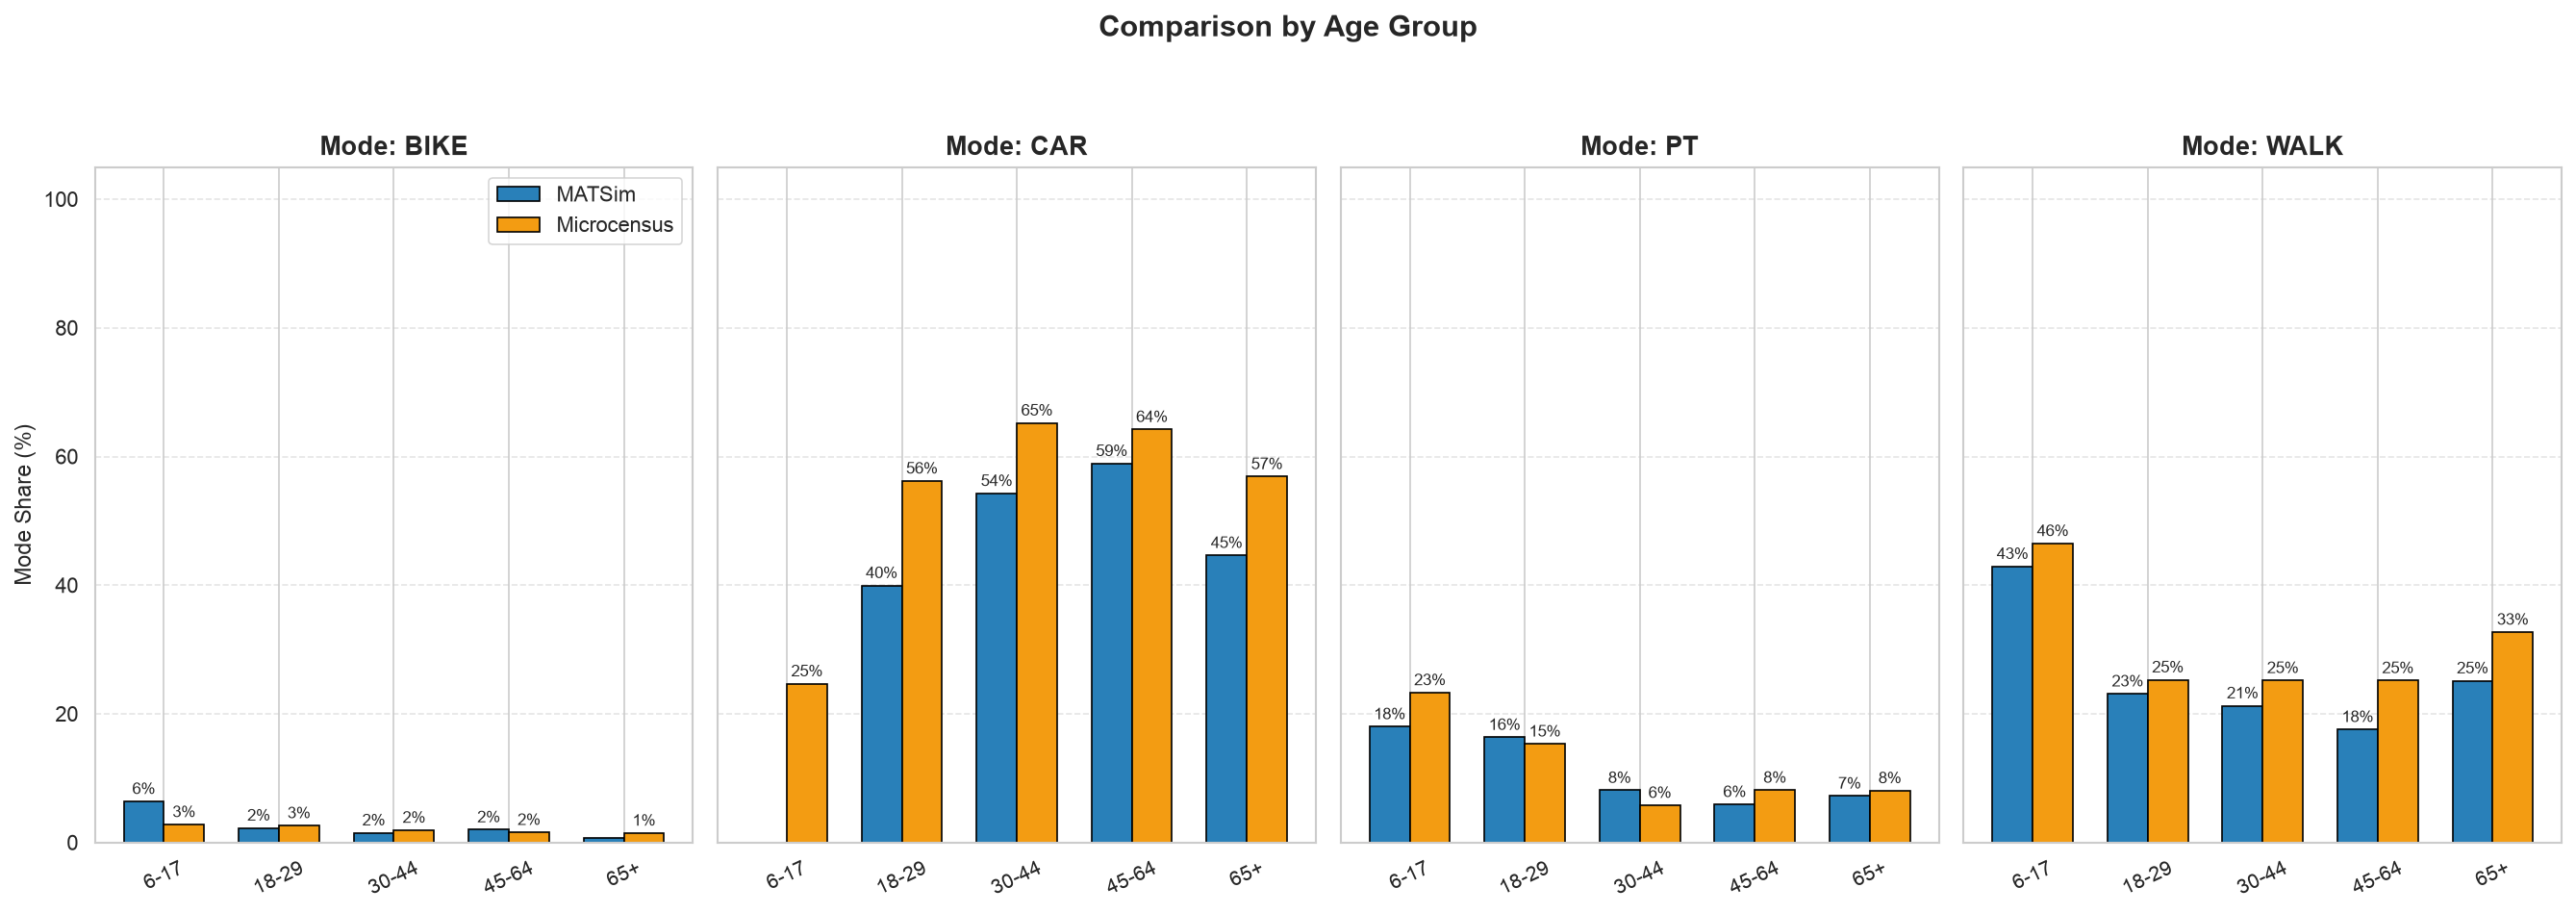

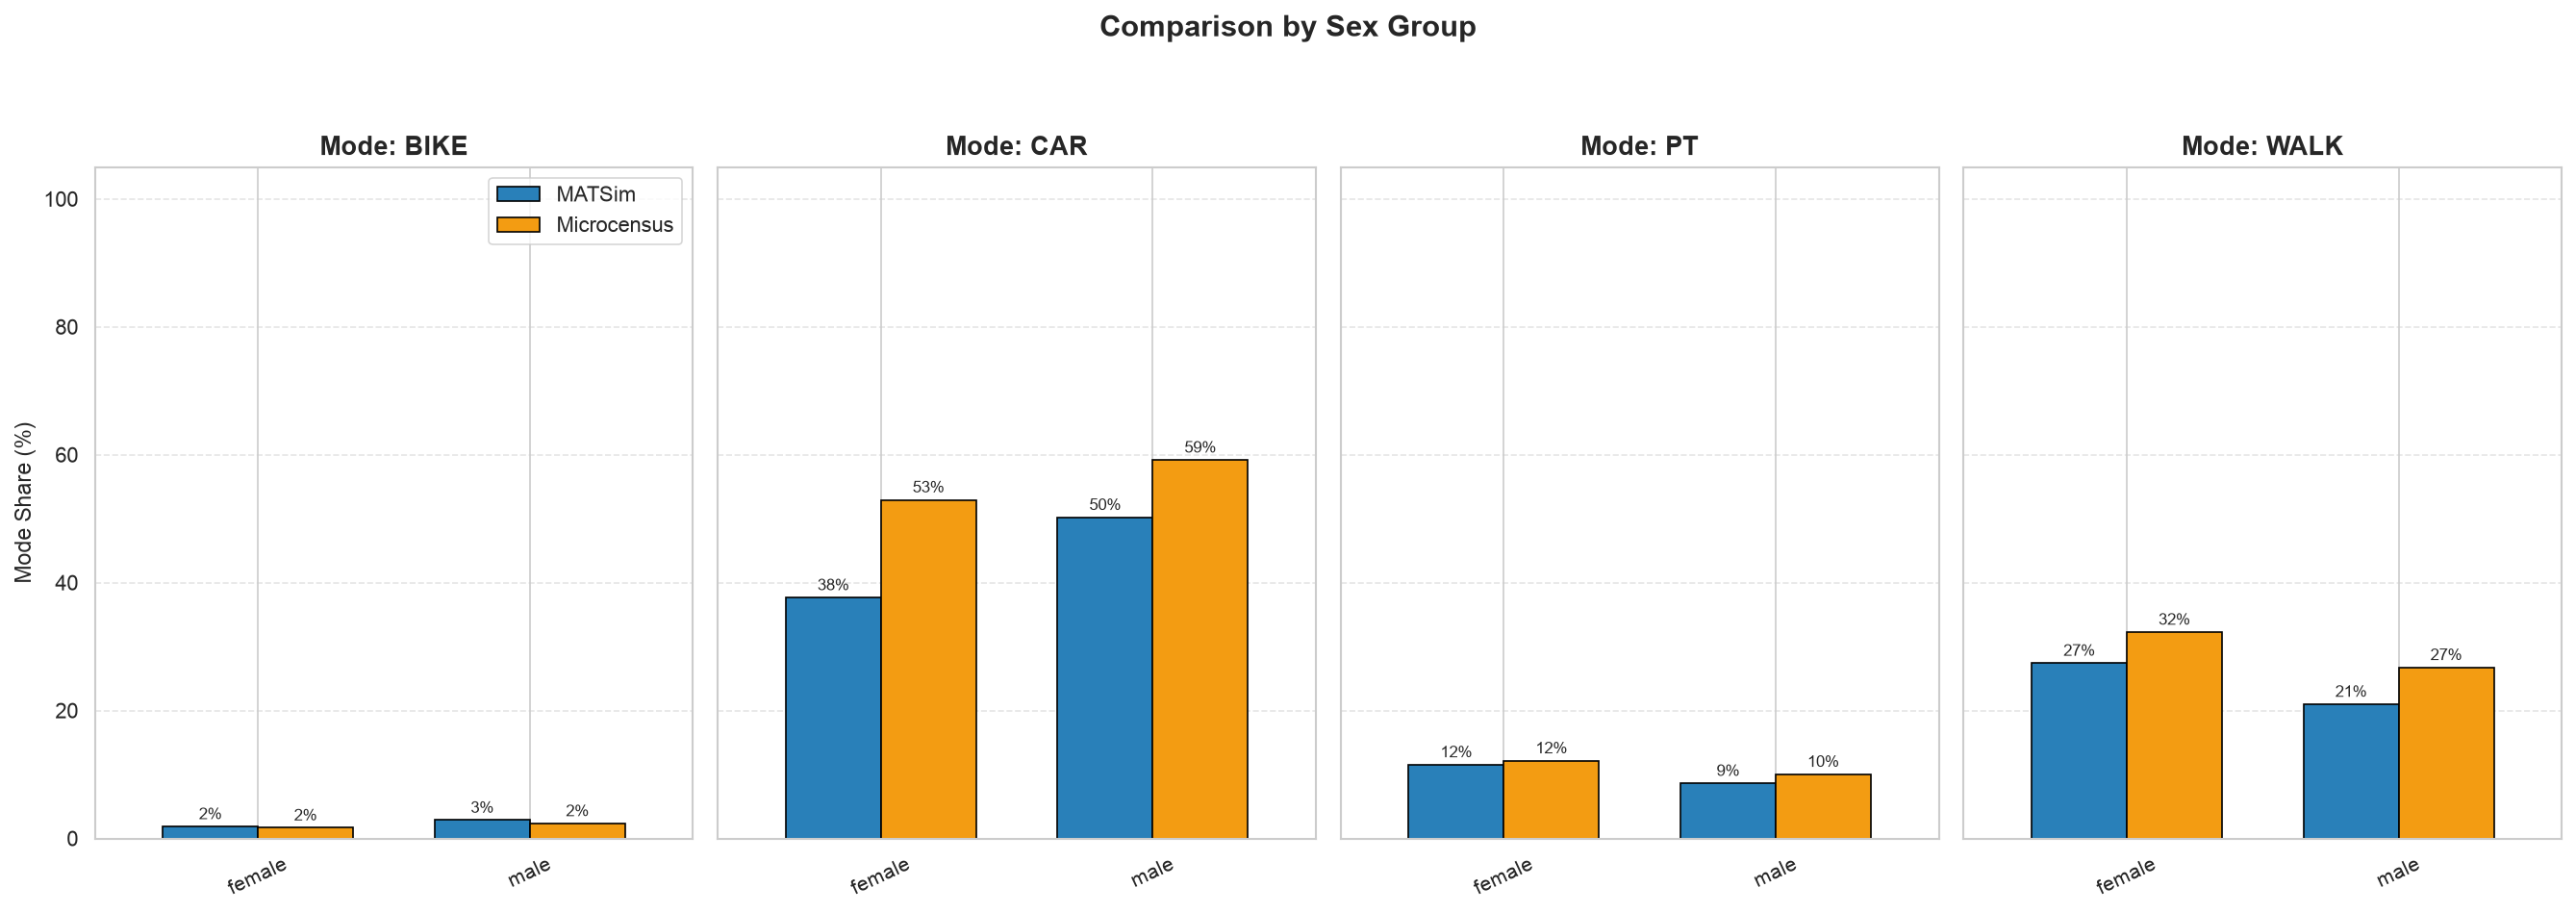

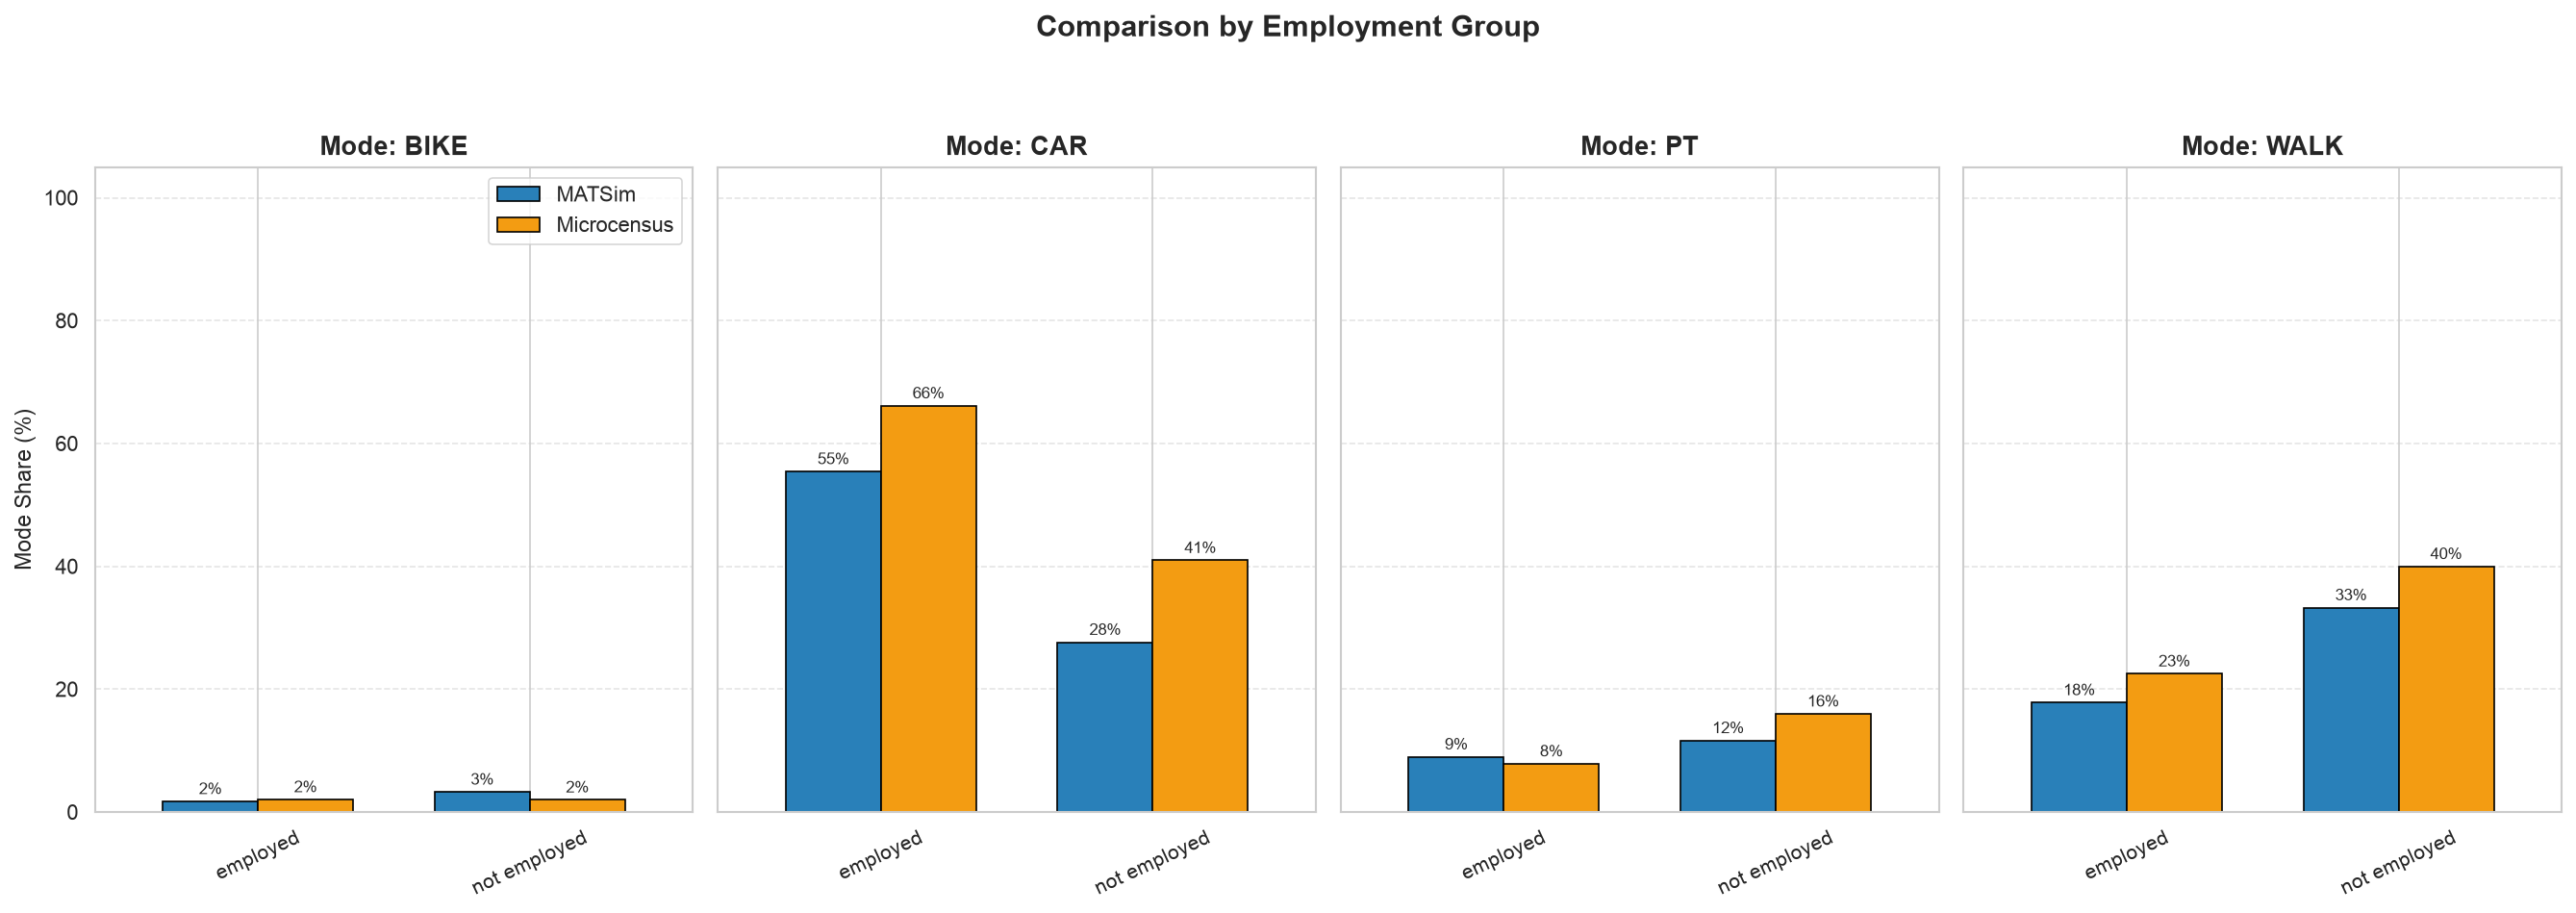

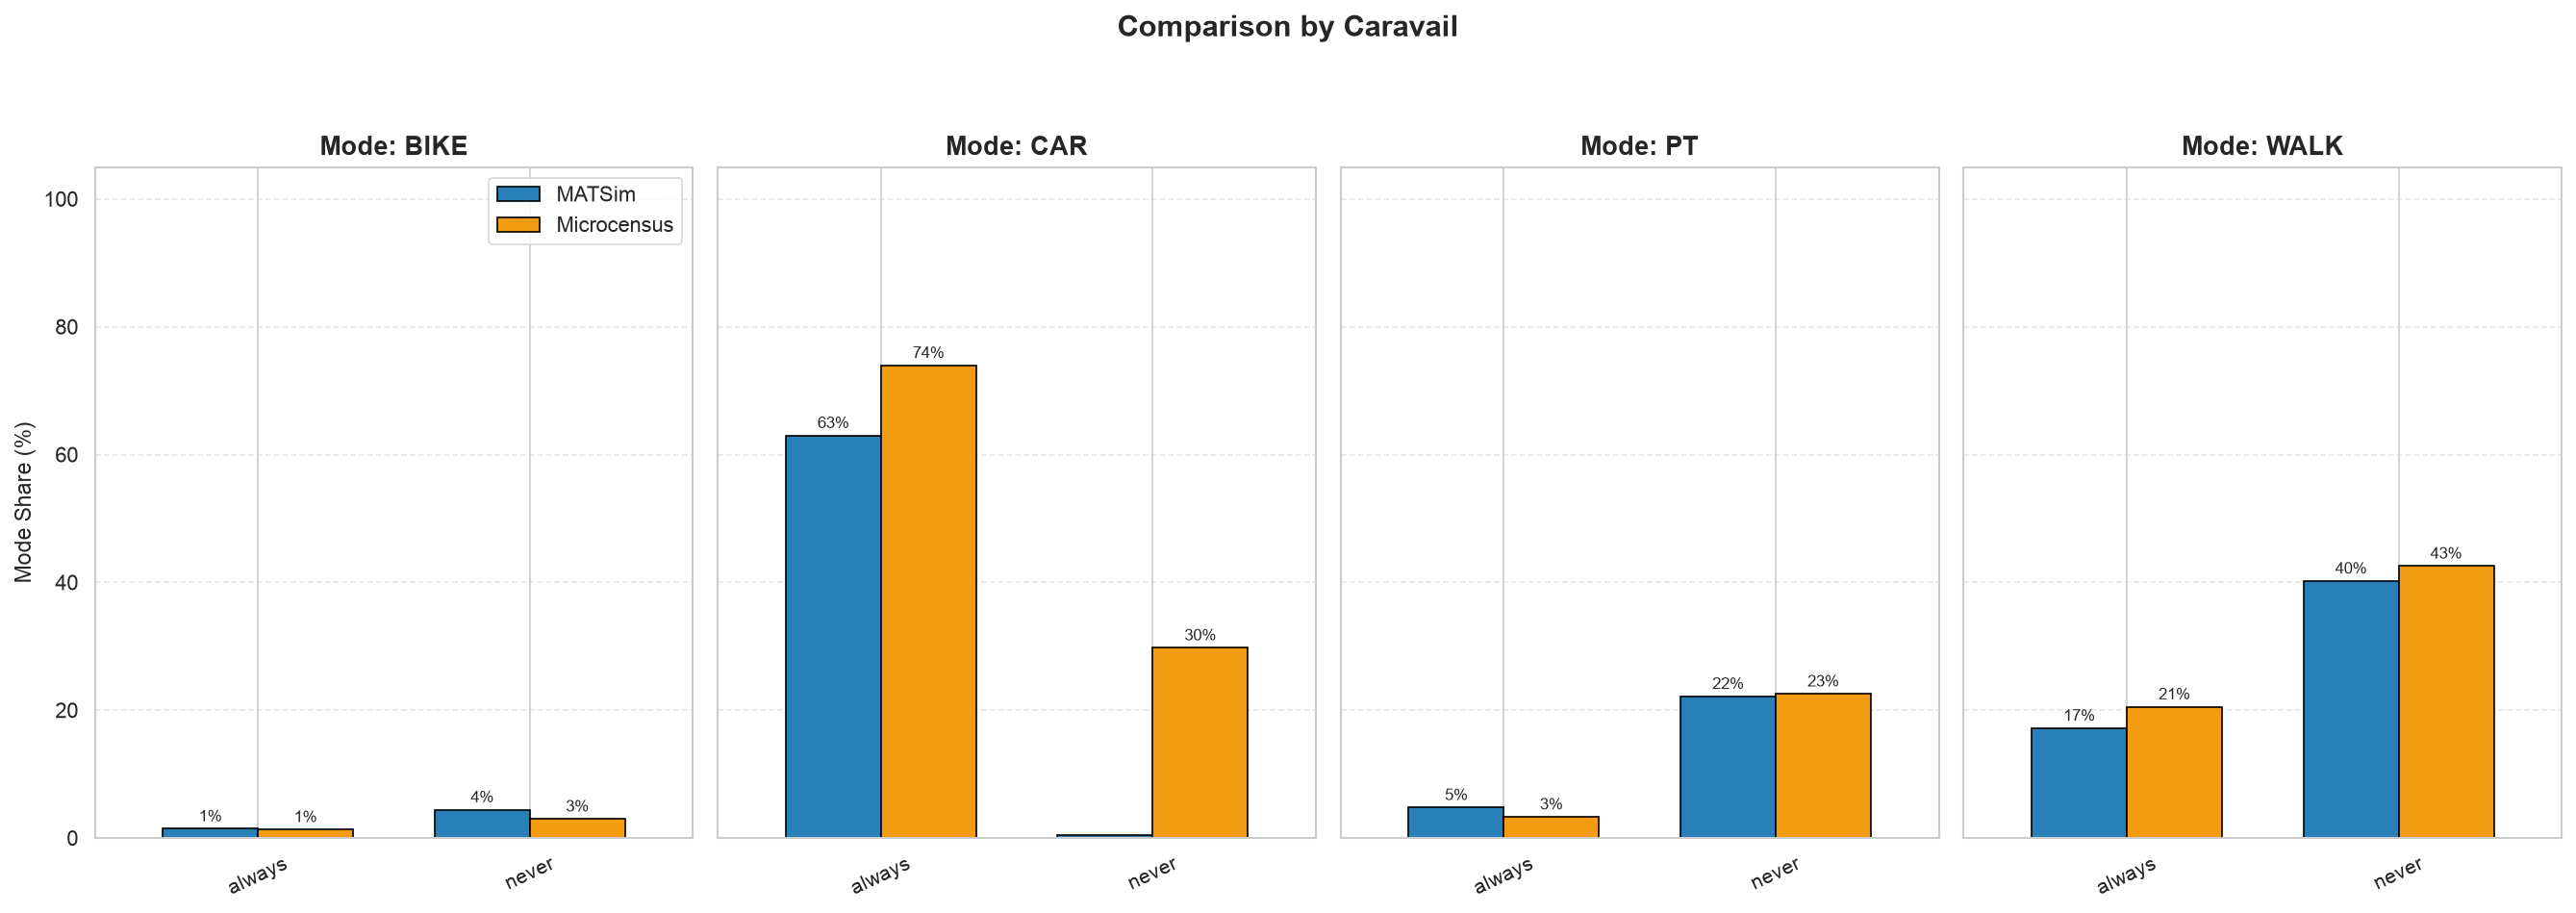

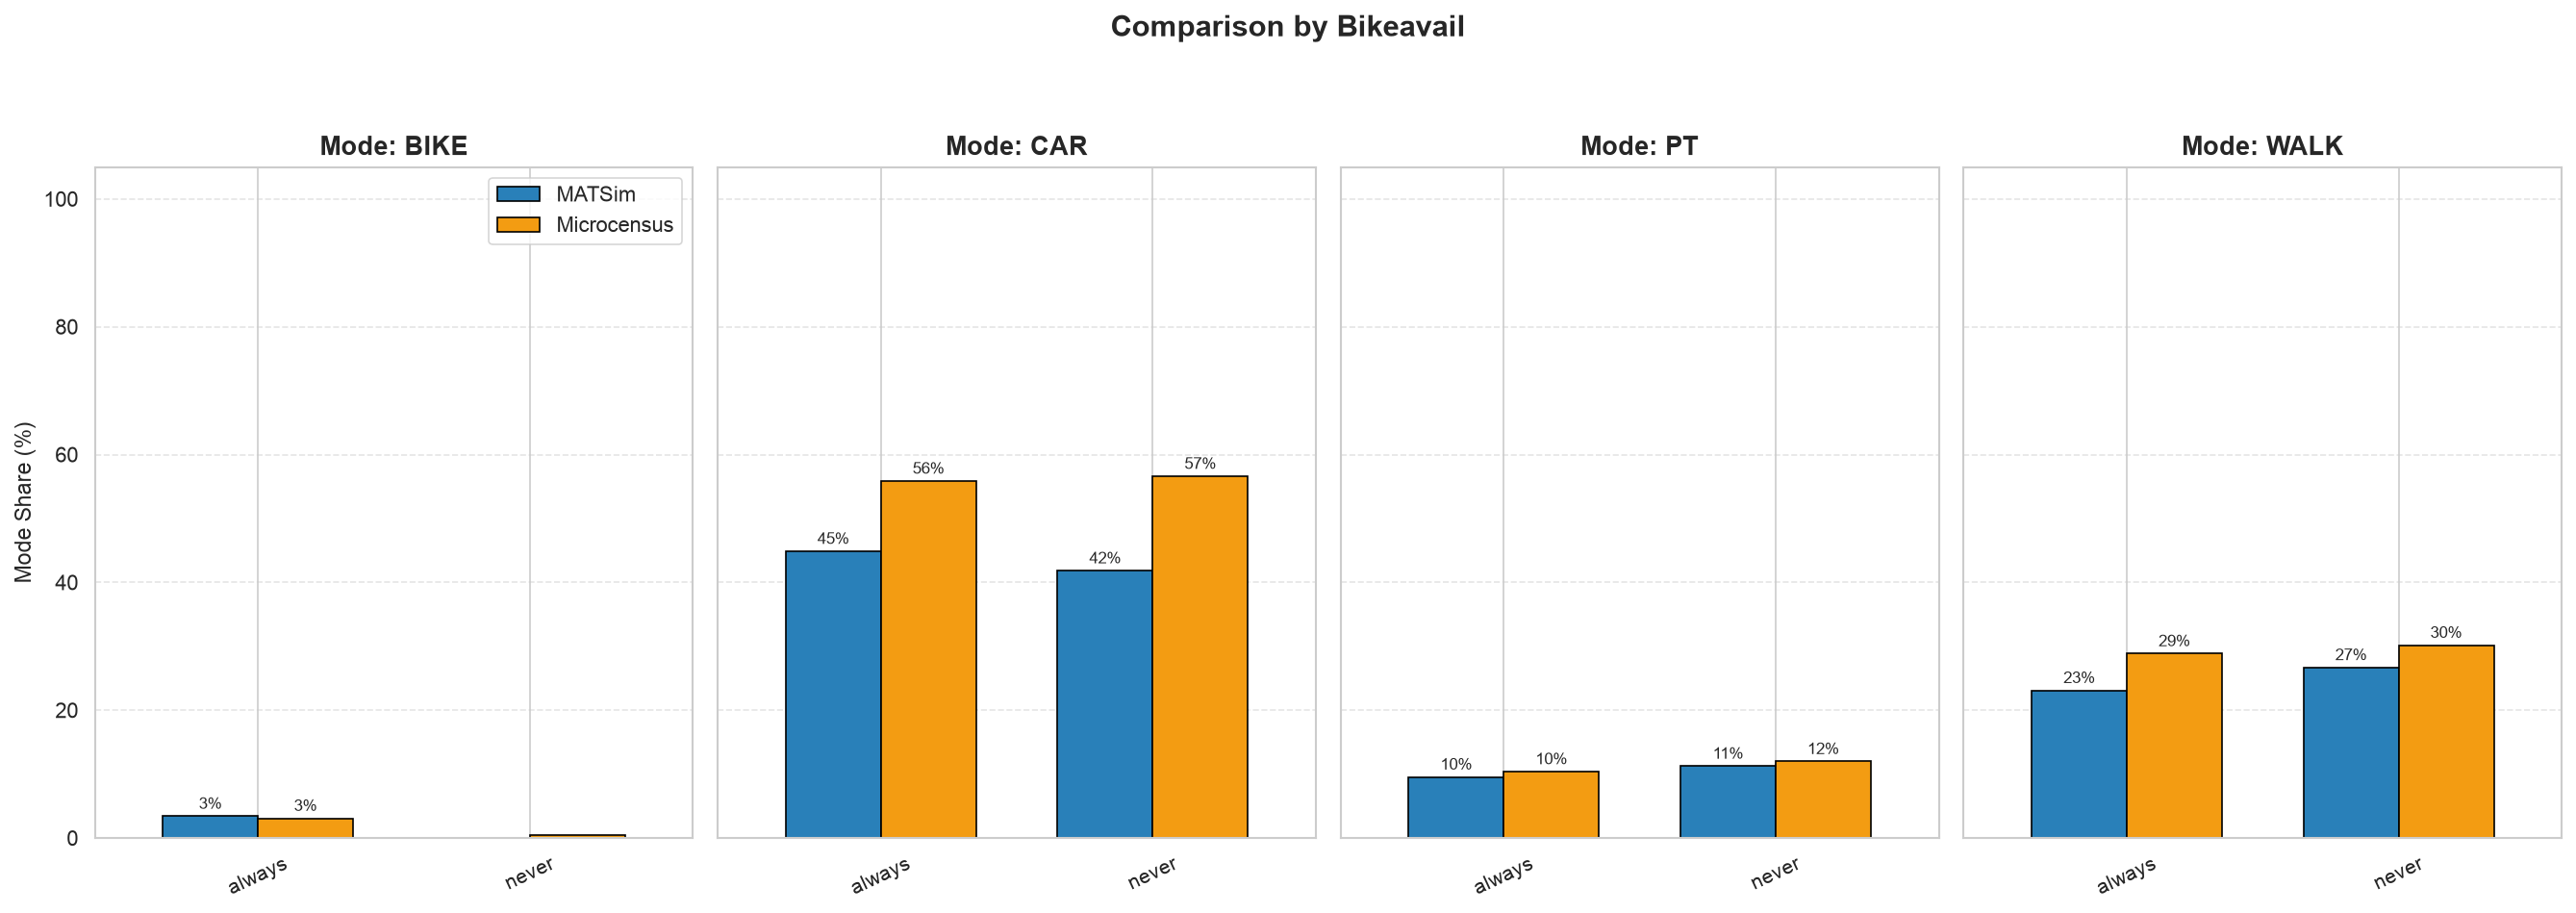

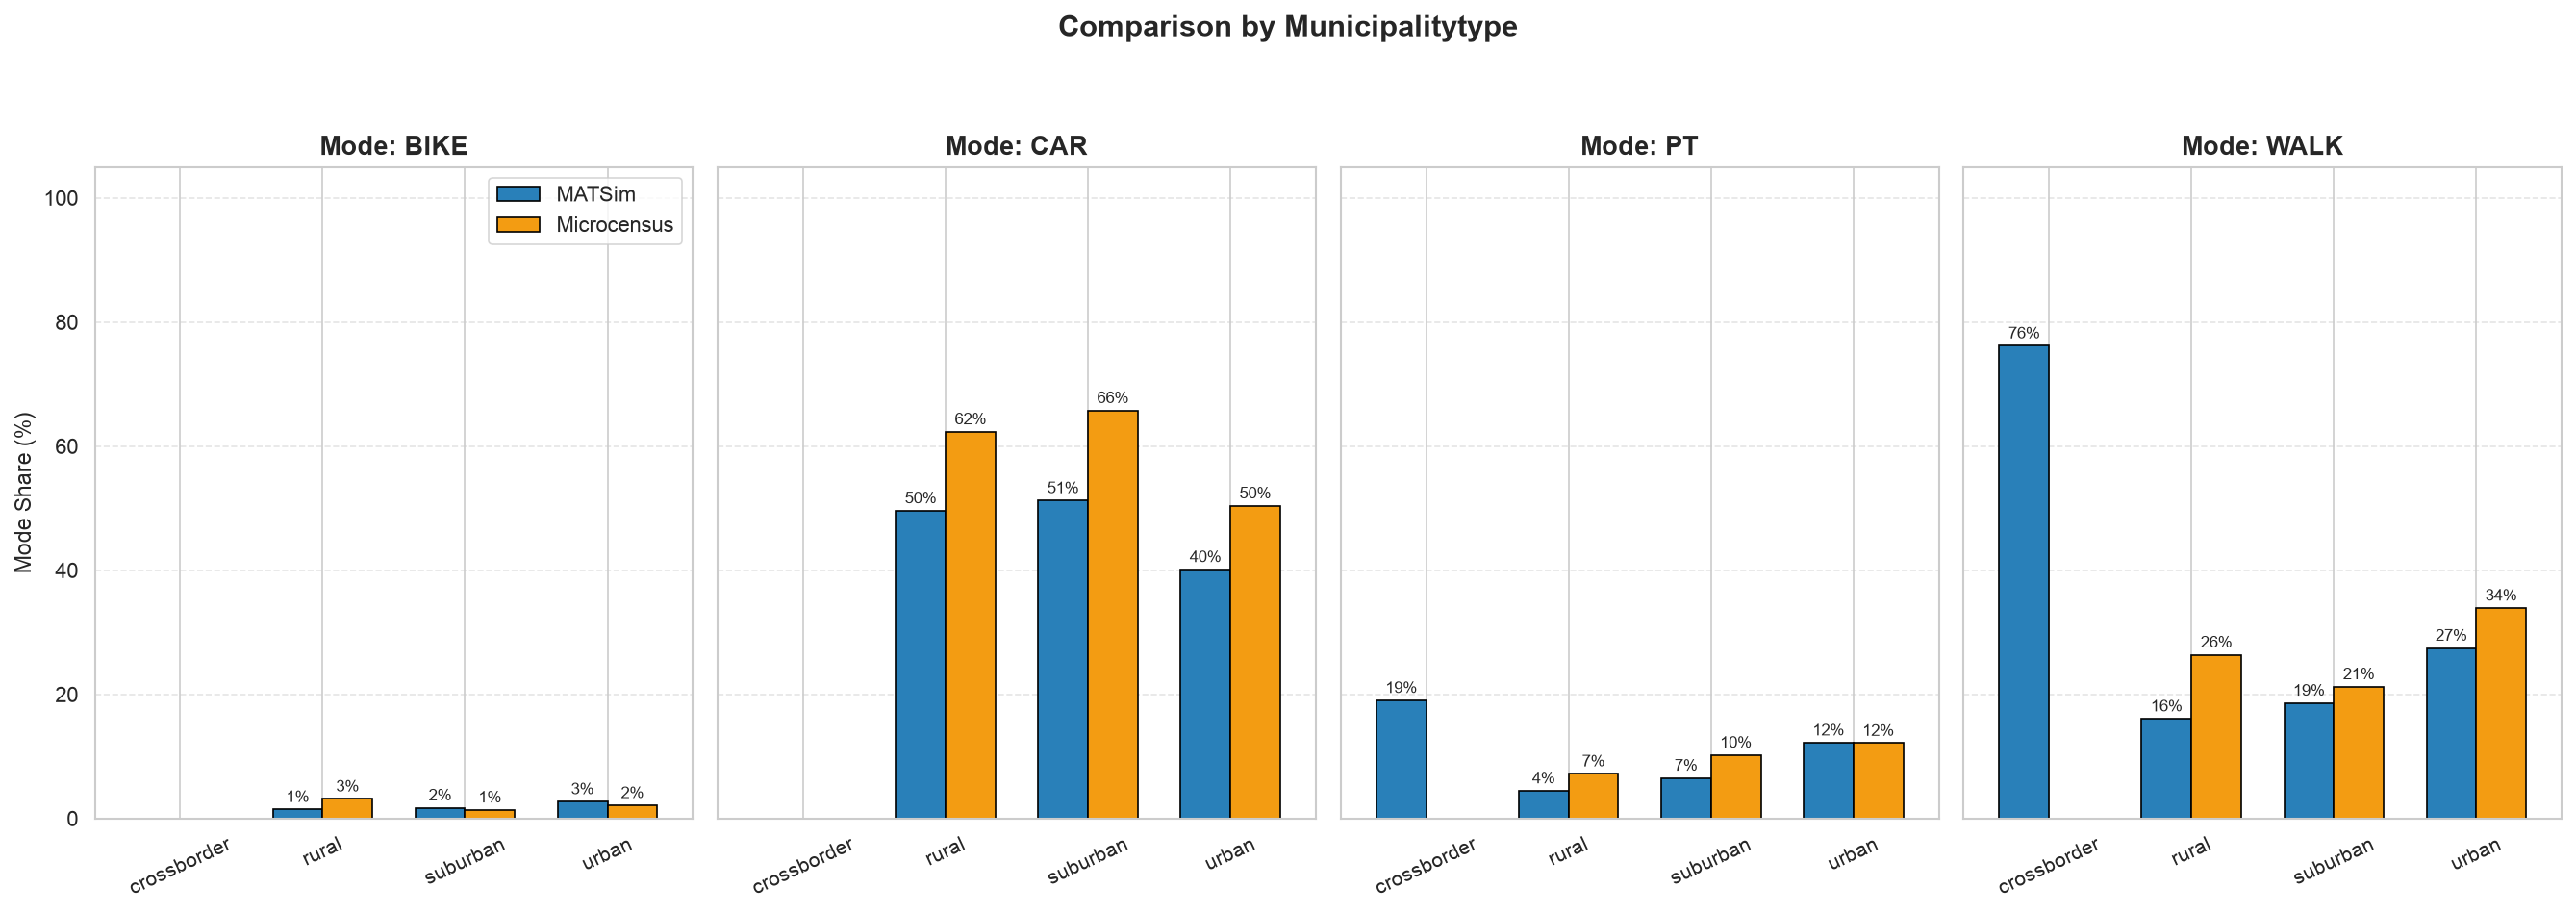

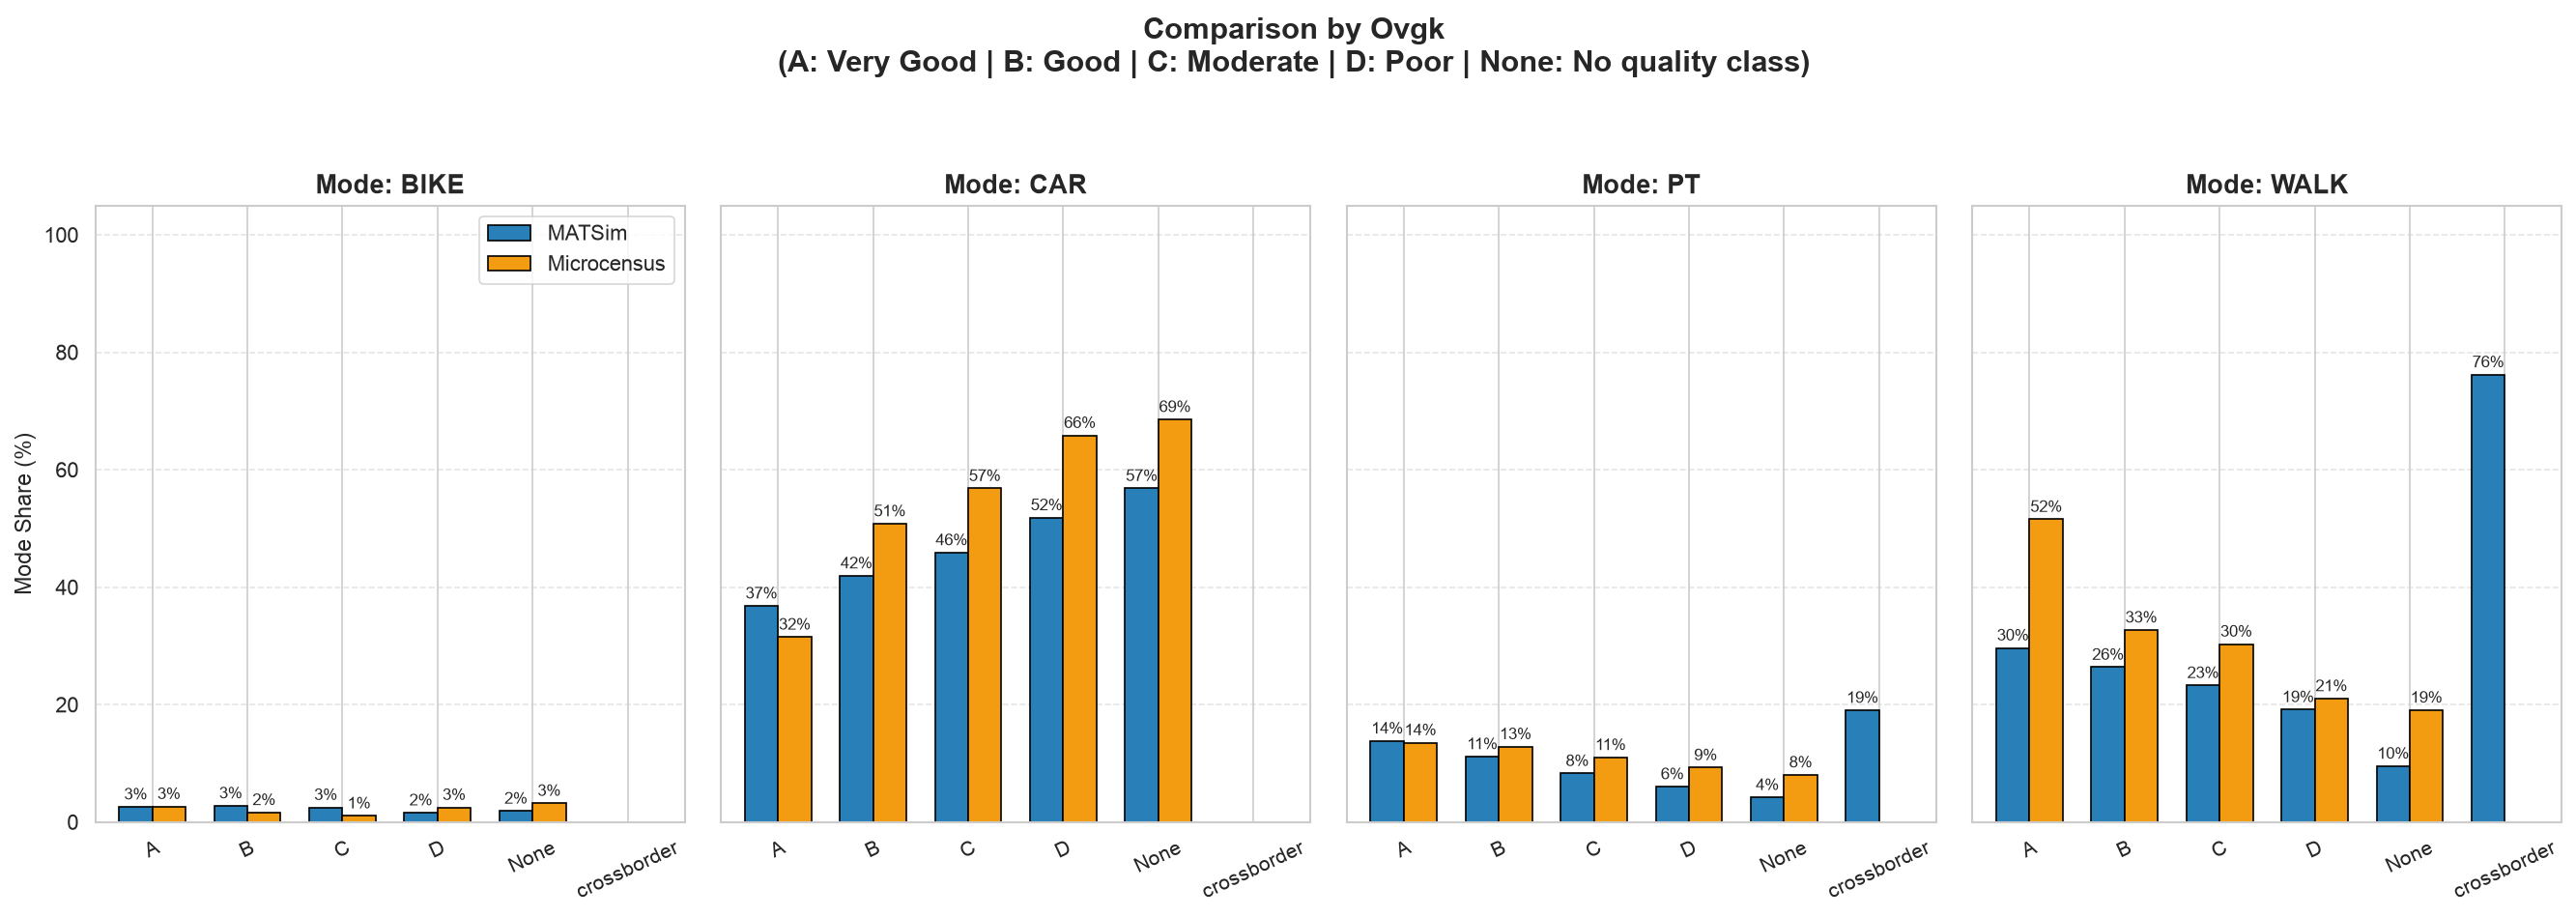

In [488]:
# ==========================================
# 3. MODE-SHARE BY SOCIO-DEMOGRAPHICS (SORTED, OPTIMIZED & ANNOTATED)
# ==========================================
def check_socio_demographics(ms, mz, modes_to_compare=['bike', 'car', 'pt', 'walk']):
    if ms.empty or mz.empty: return
    
    # --- HARMONIZATION FOR MICROZENSUS ---
    # 1. Age (Target: 6-17, 18-29, 30-44, 45-64, 65+)
    if 'alter' in mz.columns:
        mz['age_group'] = pd.cut(pd.to_numeric(mz['alter'], errors='coerce'), 
                                 bins=[6, 18, 30, 45, 65, 120], 
                                 labels=['6-17', '18-29', '30-44', '45-64', '65+'], 
                                 right=False)
    
    age_categories = ['6-17', '18-29', '30-44', '45-64', '65+']
    for df in [ms, mz]:
        if 'age_group' in df.columns:
            if hasattr(df['age_group'], 'cat'):
                df['age_group'] = df['age_group'].astype(str).str.replace("–", "-")
            df['age_group'] = pd.Categorical(df['age_group'], categories=age_categories, ordered=True)

    # 2. Sex (Target: Male, Female, Unknown)
    if 'gesl' in mz.columns:
        mz['sex_group'] = pd.to_numeric(mz['gesl'], errors='coerce').map({1: 'male', 2: 'female'}).fillna('unknown')
        
    # 3. Employment
    if 'AMSTAT' in mz.columns:
        mz['employment_group'] = pd.to_numeric(mz['AMSTAT'], errors='coerce').map(
            lambda x: 
            'employed' if x == 1 else 
            ('not employed')
        ).fillna('unknown')

    # 4. Car Availability
    if 'f42100e' in mz.columns:
        mz['carAvail'] = pd.to_numeric(mz['f42100e'], errors='coerce').map(
            lambda x: 
            'always' if (x == 1 or x == 2) else  
            ('never')).fillna('unknown')

    # 5. Bicycle Availability
    if 'f42100a' in mz.columns:
        mz['bikeAvail'] = pd.to_numeric(mz['f42100a'], errors='coerce').map(
            lambda x: 
            'always' if (x == 1 or x == 2) else 
            ('never')).fillna('unknown')

    # 6. Urbanization
    if 'hh_W_staedt_char_2012' in mz.columns:
        mz['municipalityType'] = pd.to_numeric(mz['hh_W_staedt_char_2012'], errors='coerce').map(
            {0:'rural', 1:'urban', 2:'urban', 3:'urban', 4:'suburban', 5:'suburban', 6:'rural'}
        ).fillna('Unknown')
        if 'municipalityType' in ms.columns:
            ms['municipalityType'] = ms['municipalityType'].replace({"urbancore": "urban"})

    # 7. Public Transport Class (ovgk)
    if 'hh_W_OeV_KLASSE' in mz.columns:
        mz['ovgk'] = pd.to_numeric(mz['hh_W_OeV_KLASSE'], errors='coerce').map(
            {1: 'A', 2: 'B', 3: 'C', 4: 'D', 5: 'None'}
        ).fillna('Unknown')


    # --- FEATURES TO PLOT ---
    features_to_plot = [
        'age_group', 'sex_group', 'employment_group', 
        'carAvail', 'bikeAvail', 'municipalityType',
    ]
    
    active_features = [f for f in features_to_plot if f in ms.columns and f in mz.columns]
    
    if not active_features:
        print("No harmonized socio-demographic features found in both datasets.")
        return

    # Ordbok med forklaringer som kan vises som undertittel eller infoboks for spesifikke grafer
    feature_subtitles = {
        'ovgk': 'A: Very Good | B: Good | C: Moderate | D: Poor | None: No quality class'
    }

    for feature in active_features:
        fig, axes = plt.subplots(1, len(modes_to_compare), figsize=(4.5 * len(modes_to_compare), 6.0), sharey=True)
        if len(modes_to_compare) == 1: axes = [axes]
        
        for idx, mode in enumerate(modes_to_compare):
            ax = axes[idx]
            
            ms_tot = ms.groupby(feature, observed=False).size()
            ms_mod = ms[ms['routing_modes'] == mode].groupby(feature, observed=False).size()
            ms_pct = (ms_mod / ms_tot * 100).fillna(0)
            
            mz_tot = mz.groupby(feature, observed=False)['WP'].sum()
            mz_mod = mz[mz['mode'] == mode].groupby(feature, observed=False)['WP'].sum()
            mz_pct = (mz_mod / mz_tot * 100).fillna(0)
            
            df_comp = pd.DataFrame({'MATSim': ms_pct, 'Microcensus': mz_pct}).fillna(0)
            
            if feature == 'age_group':
                existing_cats = [c for c in age_categories if c in df_comp.index]
                df_comp = df_comp.reindex(existing_cats)

            df_comp.plot(kind='bar', ax=ax, color=['#2980b9', '#f39c12'], edgecolor='black', width=0.7, legend=(idx == 0))
            
            ax.set_title(f'Mode: {mode.upper()}', fontsize=13, weight='bold')
            ax.set_ylabel('Mode Share (%)' if idx == 0 else '', fontsize=11)
            ax.set_xlabel('')
            
            ax.tick_params(axis='x', rotation=25, labelsize=10)
            ax.grid(axis='y', linestyle='--', alpha=0.5)
            ax.set_ylim(0, 105)
            
            for p in ax.patches:
                height = p.get_height()
                if height > 1:
                    ax.annotate(f"{height:.0f}%", 
                                (p.get_x() + p.get_width() / 2., height), 
                                ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')

            if idx > 0 and ax.get_legend() is not None:
                ax.get_legend().remove()

        # Legg til en ekstra undertekst (forklaring) spesifikt for OVGK-grafen
        suptitle_text = f'Comparison by {feature.replace("_", " ").title()}'
        if feature in feature_subtitles:
            suptitle_text += f'\n({feature_subtitles[feature]})'

        plt.suptitle(suptitle_text, fontsize=15, weight='bold', y=1.05)
        plt.tight_layout()
        plt.show()

check_socio_demographics(ms_df, mz_df)

## 5. Spatial Differences in Mode-Choice
We assess spatial discrepancies in mode choice by visualizing where trips originate. The Microcensus household coordinates are mapped in the CH1903 system.



/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_12658/855900979.py:72: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mz_df["hh_W_X_2056"], mz_df["hh_W_Y_2056"] = gpd.GeoDataFrame(mz_df, geometry=gpd.points_from_xy(mz_df["hh_W_X_CH1903"], mz_df["hh_W_Y_CH1903"]), crs=21781).to_crs(2056).geometry.x, gpd.GeoDataFrame(mz_df, geometry=gpd.points_from_xy(mz_df["hh_W_X_CH1903"], mz_df["hh_W_Y_CH1903"]), crs=21781).to_crs(2056).geometry.y
/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_12658/855900979.py:73: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented

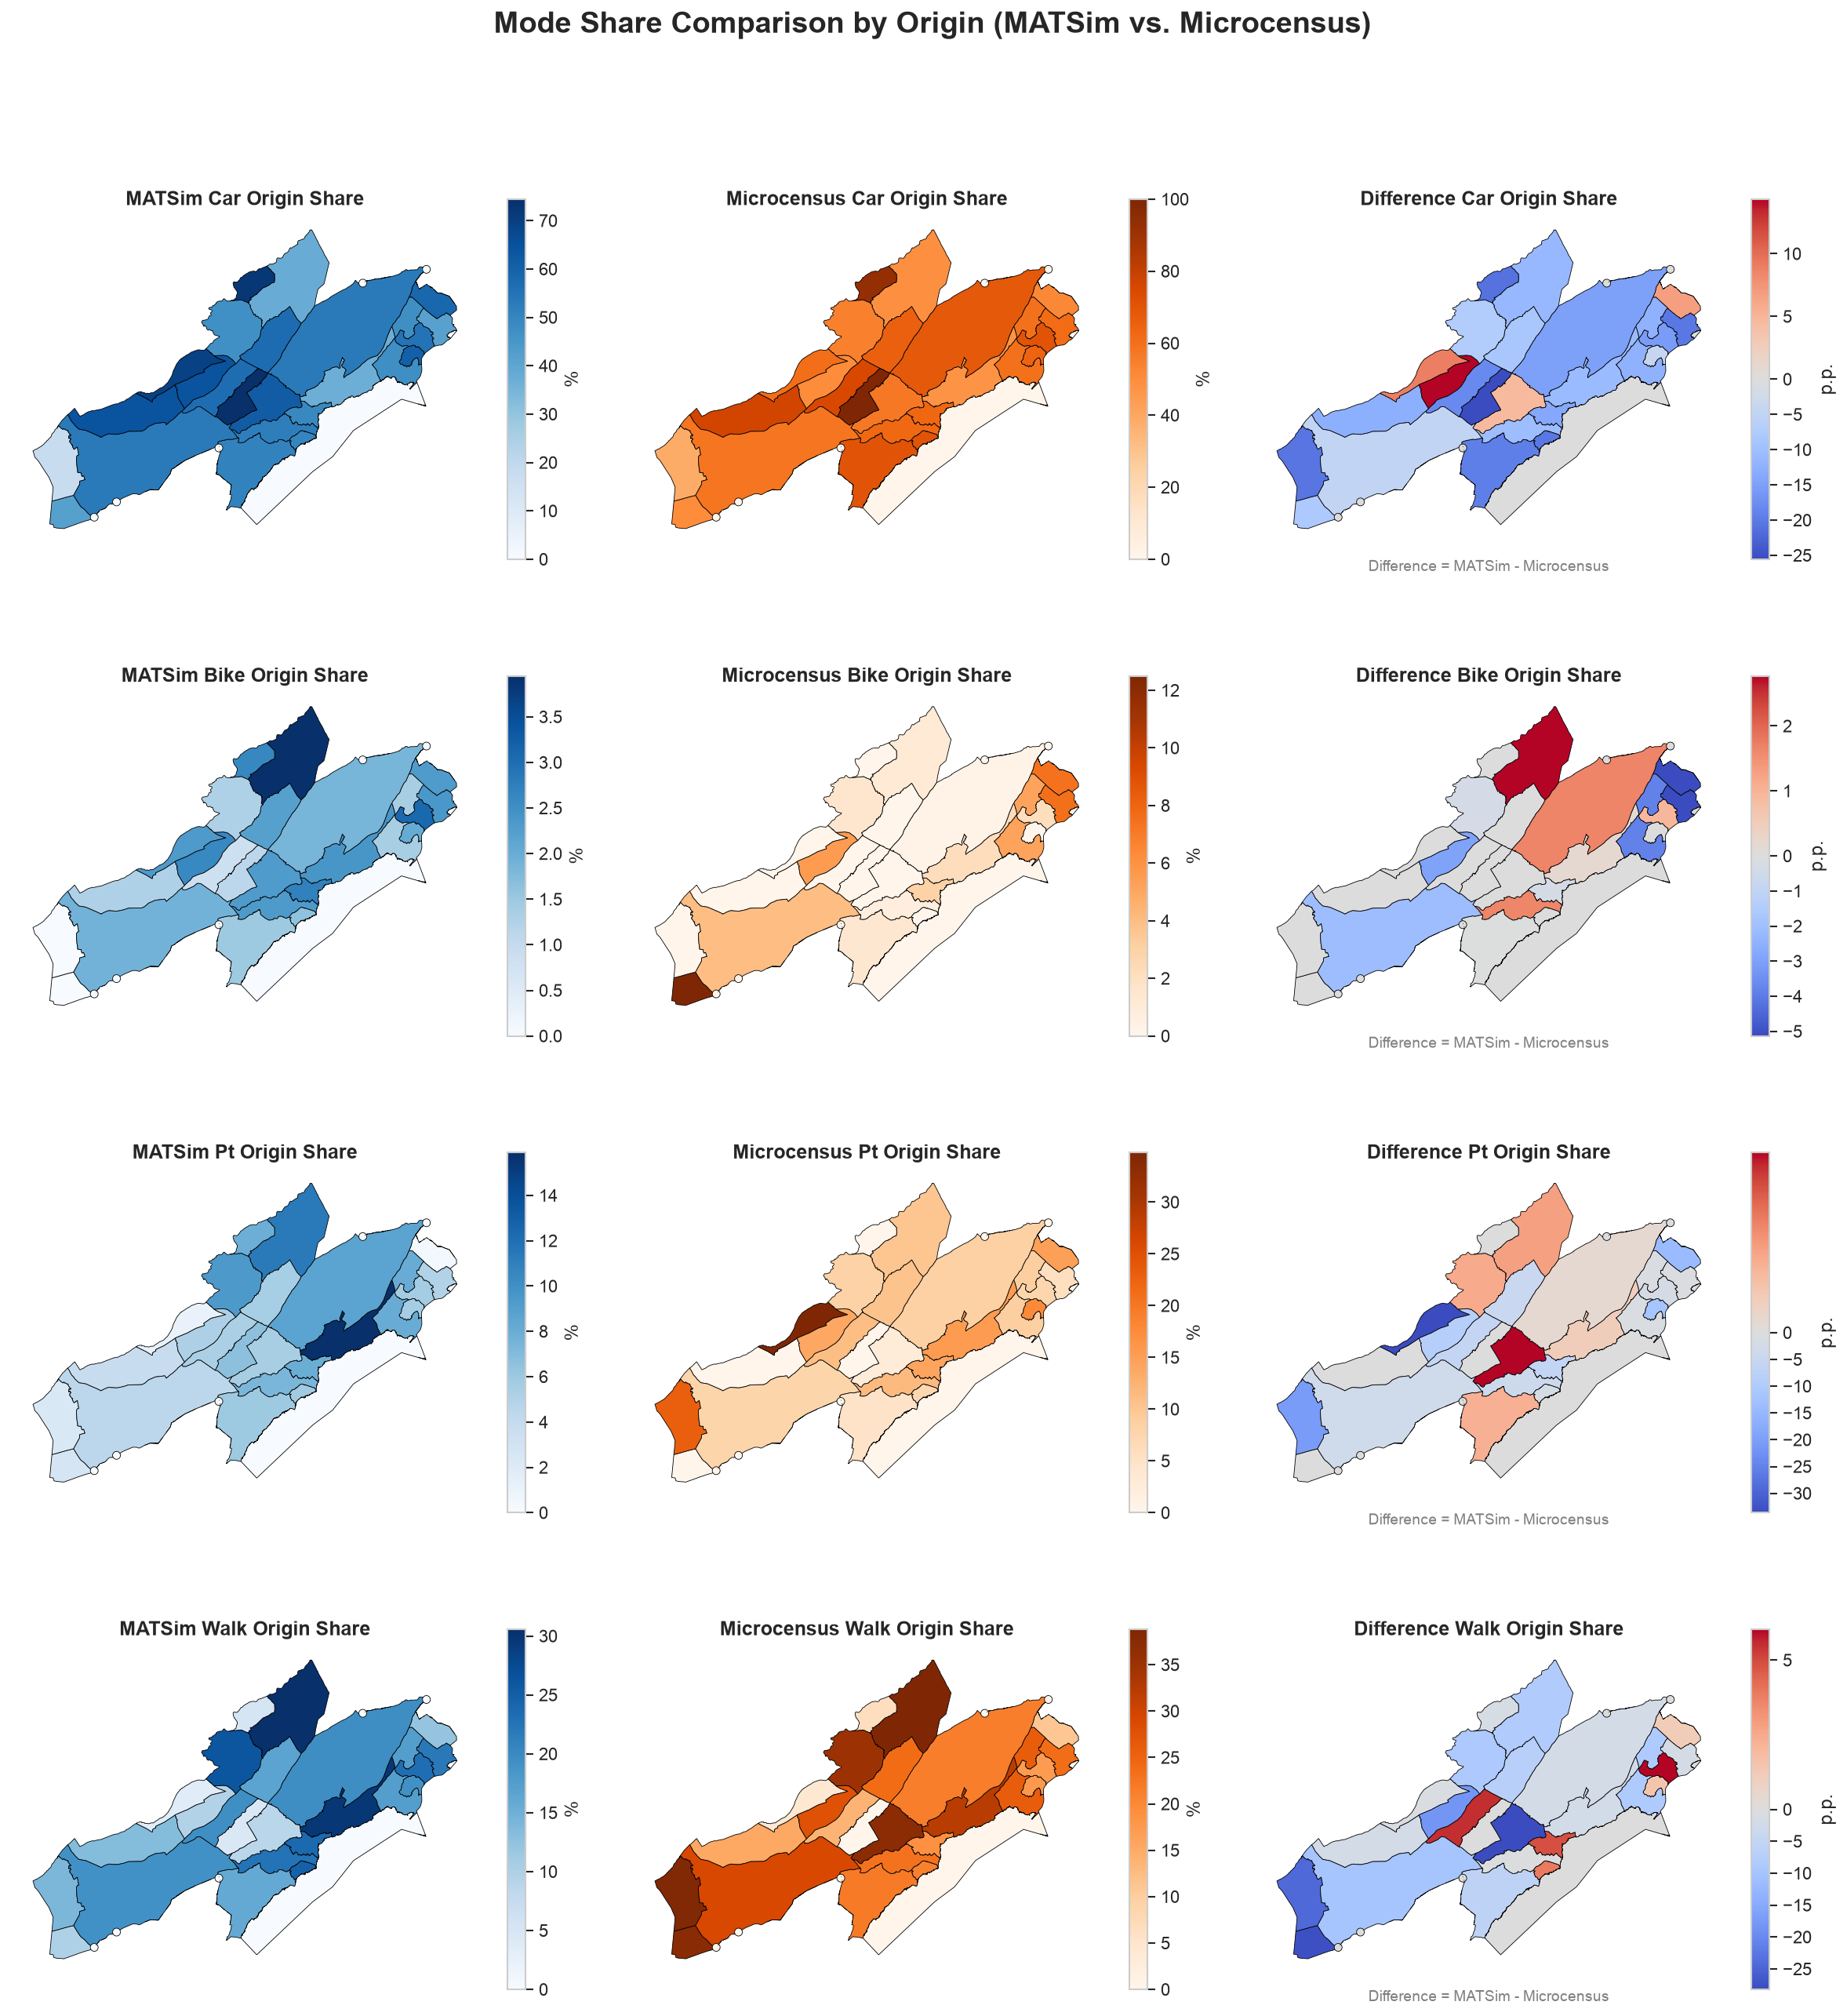

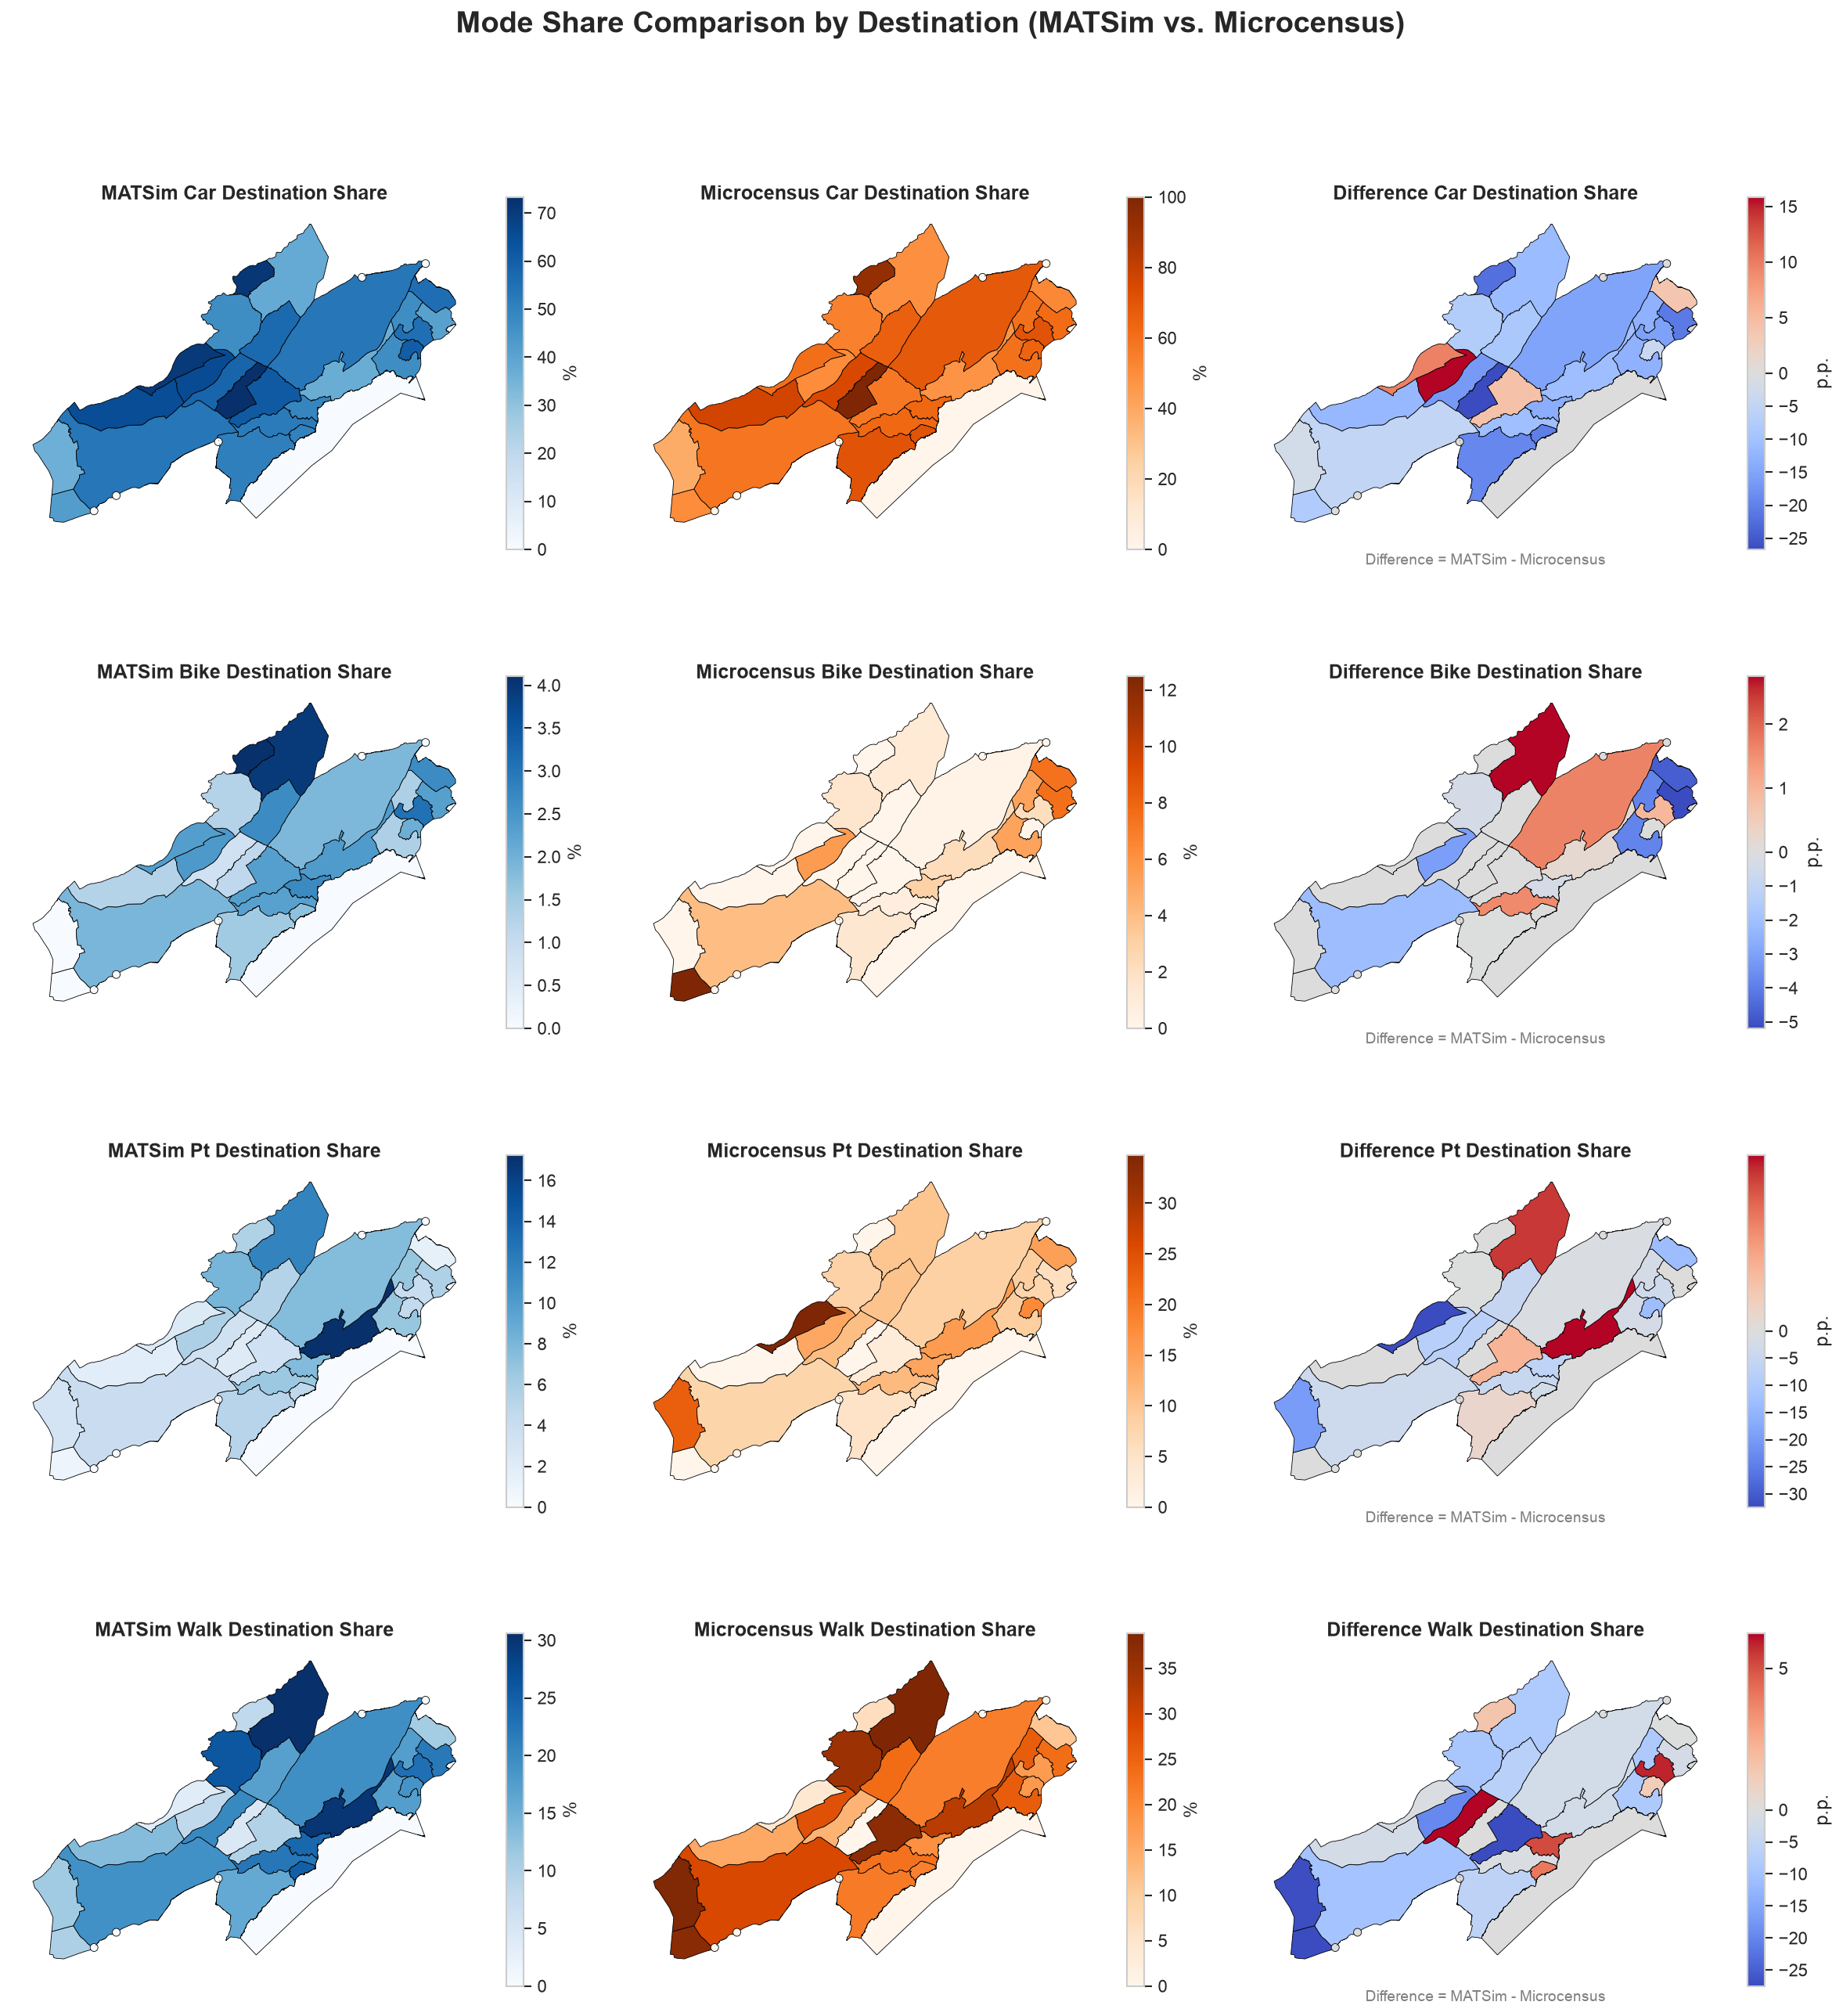

In [489]:
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


import geopandas as gpd
import numpy as np
import pandas as pd

# 1. Load boundary and combine geometry
boundary = gpd.read_file('Boundary/neuchatel.shp').to_crs(2056)
region = boundary.geometry.union_all()

ADMIN_PATH = 'Boundary/neuchatel_municipalities_2025.gpkg'

# Fix 1: Use 'tlm_hoheitsgebiet' instead of 'municipalities' (swisstopo GPKG schema)
areas = gpd.read_file(ADMIN_PATH, layer='tlm_hoheitsgebiet').to_crs(2056)

# Categorize area type
areas['area_type'] = np.where(
    areas['objektart'].eq('Gemeindegebiet'), 
    'Municipality', 
    'Canton lake territory'
)

# Fix 2: Handle potential missing/NaN values in bfs_nummer safely before integer cast
areas['cell'] = pd.to_numeric(areas['bfs_nummer'], errors='coerce').fillna(0).astype(int).astype(str)
areas['area_name'] = areas['name']

# Clip geometries to canton boundary
areas['geometry'] = areas.geometry.intersection(region)

# Filter out empty or non-polygon artifacts
areas = areas.loc[
    ~areas.geometry.is_empty & areas.geometry.area.gt(0),
    ['cell', 'area_name', 'area_type', 'geometry']
].copy()

# Dissolve by municipality BFS number
areas = areas.dissolve(by='cell', aggfunc='first').reset_index()

# Calculate residual/remainder geometry
residual = region.difference(areas.geometry.union_all())

if not residual.is_empty and residual.area > 0:
    remainder_df = gpd.GeoDataFrame(
        [{
            'cell': '999999',
            'area_name': 'Boundary remainder (unassigned)',
            'area_type': 'Boundary remainder',
            'geometry': residual
        }],
        crs=2056
    )
    areas = pd.concat([areas, remainder_df], ignore_index=True)

areas = gpd.GeoDataFrame(areas, crs=2056)

ms_df["area_name_origin"] = gpd.sjoin(
    gpd.GeoDataFrame(ms_df, geometry=gpd.points_from_xy(ms_df["origin_x"], ms_df["origin_y"]), crs=2056),
    areas[['cell', 'area_name', 'geometry']],
    how="left",
    predicate="within"
)["area_name"]

ms_df["area_name_destination"] = gpd.sjoin(
    gpd.GeoDataFrame(ms_df, geometry=gpd.points_from_xy(ms_df["destination_x"], ms_df["destination_y"]), crs=2056),
    areas[['cell', 'area_name', 'geometry']],
    how="left",
    predicate="within"
)["area_name"]

mz_df["hh_W_X_2056"], mz_df["hh_W_Y_2056"] = gpd.GeoDataFrame(mz_df, geometry=gpd.points_from_xy(mz_df["hh_W_X_CH1903"], mz_df["hh_W_Y_CH1903"]), crs=21781).to_crs(2056).geometry.x, gpd.GeoDataFrame(mz_df, geometry=gpd.points_from_xy(mz_df["hh_W_X_CH1903"], mz_df["hh_W_Y_CH1903"]), crs=21781).to_crs(2056).geometry.y
mz_df["area_name_origin"] = gpd.sjoin(
    gpd.GeoDataFrame(mz_df, geometry=gpd.points_from_xy(mz_df["hh_W_X_2056"], mz_df["hh_W_Y_2056"]), crs=2056),
    areas[['cell', 'area_name', 'geometry']],
    how="left",
    predicate="within"
)["area_name"]

mz_df["area_name_destination"] = gpd.sjoin(
    gpd.GeoDataFrame(mz_df, geometry=gpd.points_from_xy(mz_df["hh_W_X_2056"], mz_df["hh_W_Y_2056"]), crs=2056),
    areas[['cell', 'area_name', 'geometry']],
    how="left",
    predicate="within"
)["area_name"]

""" a = ms_df[ms_df['routing_modes'] == "bike"].groupby('area_name_origin').size()
a =a.to_frame(name='bike_origin_ms')
print(a)
#replace NaN with 0 for areas with no bike trips
b = areas.merge(a, left_on='area_name', right_index=True, how='left')
b['bike_origin_ms'] = b['bike_origin_ms'].fillna(0)
print(b)
 """
transport_modes = ['car', 'bike', 'pt', 'walk']
for mode in transport_modes:
    ms_df_origin = (ms_df[ms_df['routing_modes'] == mode].groupby('area_name_origin').size()/ms_df.groupby('area_name_origin').size() * 100).to_frame(name=mode + '_origin_ms')
    ms_df_destination = (ms_df[ms_df['routing_modes'] == mode].groupby('area_name_destination').size()/ms_df.groupby('area_name_destination').size() * 100).to_frame(name=mode + '_destination_ms')
    mz_df_origin = (mz_df[mz_df['mode'] == mode].groupby('area_name_origin').size()/mz_df.groupby('area_name_origin').size() * 100).to_frame(name=mode + '_origin_mz')
    mz_df_destination = (mz_df[mz_df['mode'] == mode].groupby('area_name_destination').size()/mz_df.groupby('area_name_destination').size() * 100).to_frame(name=mode + '_destination_mz')
    origin_diff = ms_df_origin[mode + '_origin_ms'] - mz_df_origin[mode + '_origin_mz']
    destination_diff = ms_df_destination[mode + '_destination_ms'] - mz_df_destination[mode + '_destination_mz']
    areas = areas.merge(ms_df_origin, left_on='area_name', right_index=True, how='left').fillna(0)
    areas = areas.merge(ms_df_destination, left_on='area_name', right_index=True, how='left').fillna(0)
    areas = areas.merge(mz_df_origin, left_on='area_name', right_index=True, how='left').fillna(0)
    areas = areas.merge(mz_df_destination, left_on='area_name', right_index=True, how='left').fillna(0)
    areas = areas.merge(origin_diff.to_frame(name=mode + '_origin_diff'), left_on='area_name', right_index=True, how='left').fillna(0)
    areas = areas.merge(destination_diff.to_frame(name=mode + '_destination_diff'), left_on='area_name', right_index=True, how='left').fillna(0)

    #areas = areas.merge((ms_df[ms_df['routing_modes'] == mode].groupby('area_name_origin').size()/ms_df.groupby('area_name_origin').size() * 100).to_frame(name=mode + '_origin_ms'), left_on='area_name', right_index=True, how='left').fillna(0)
    #areas = areas.merge((mz_df[mz_df['mode'] == mode].groupby('area_name_origin').size()/mz_df.groupby('area_name_origin').size() * 100).to_frame(name=mode + '_origin_mz'), left_on='area_name', right_index=True, how='left').fillna(0)

    #areas = areas.merge((ms_df[ms_df['routing_modes'] == mode].groupby('area_name_destination').size()/ms_df.groupby('area_name_destination').size() * 100).to_frame(name=mode + '_destination_ms'), left_on='area_name', right_index=True, how='left').fillna(0)
    #areas = areas.merge((mz_df[mz_df['mode'] == mode].groupby('area_name_destination').size()/mz_df.groupby('area_name_destination').size() * 100).to_frame(name=mode + '_destination_mz'), left_on='area_name', right_index=True, how='left').fillna(0)

areas.head()
# ---------------------------------------------------------
# 1. Transport Modes - ORIGIN
# ---------------------------------------------------------
fig, axes = plt.subplots(4, 3, figsize=(16, 18))
fig.suptitle('Mode Share Comparison by Origin (MATSim vs. Microcensus)', fontsize=18, fontweight='bold', y=0.98)

for i, mode in enumerate(transport_modes):
    mode_cap = mode.capitalize()

    # MATSim Origin
    areas.plot(
        column=mode + '_origin_ms', 
        ax=axes[i, 0], 
        cmap='Blues', 
        legend=True, 
        edgecolor='black', 
        linewidth=0.4,
        legend_kwds={'shrink': 0.7, 'label': '%'}
    )
    axes[i, 0].set_title(f'MATSim {mode_cap} Origin Share', fontsize=12, fontweight='bold')
    axes[i, 0].axis('off')

    # Microcensus Origin
    areas.plot(
        column=mode + '_origin_mz', 
        ax=axes[i, 1], 
        cmap='Oranges', 
        legend=True, 
        edgecolor='black', 
        linewidth=0.4,
        legend_kwds={'shrink': 0.7, 'label': '%'}
    )
    axes[i, 1].set_title(f'Microcensus {mode_cap} Origin Share', fontsize=12, fontweight='bold')
    axes[i, 1].axis('off')

    # Difference Origin (0 er alltid hvit)
    diff_col = mode + '_origin_diff'
    vmin_val = min(areas[diff_col].min(), -0.001)
    vmax_val = max(areas[diff_col].max(), 0.001)
    norm_diff = TwoSlopeNorm(vmin=vmin_val, vcenter=0, vmax=vmax_val)

    areas.plot(
        column=diff_col, 
        ax=axes[i, 2], 
        cmap='coolwarm', 
        norm=norm_diff,
        legend=True, 
        edgecolor='black', 
        linewidth=0.4,
        legend_kwds={'shrink': 0.7, 'label': 'p.p.'}
    )
    axes[i, 2].set_title(f'Difference {mode_cap} Origin Share', fontsize=12, fontweight='bold')
    axes[i, 2].text(
        0.5, -0.05, "Difference = MATSim - Microcensus", 
        fontsize=9, color='gray', transform=axes[i, 2].transAxes, 
        ha='center', va='top'
    )
    axes[i, 2].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


# ---------------------------------------------------------
# 2. Transport Modes - DESTINATION
# ---------------------------------------------------------
fig, axes = plt.subplots(4, 3, figsize=(16, 18))
fig.suptitle('Mode Share Comparison by Destination (MATSim vs. Microcensus)', fontsize=18, fontweight='bold', y=0.98)

for i, mode in enumerate(transport_modes):
    mode_cap = mode.capitalize()

    # MATSim Destination
    areas.plot(
        column=mode + '_destination_ms', 
        ax=axes[i, 0], 
        cmap='Blues', 
        legend=True, 
        edgecolor='black', 
        linewidth=0.4,
        legend_kwds={'shrink': 0.7, 'label': '%'}
    )
    axes[i, 0].set_title(f'MATSim {mode_cap} Destination Share', fontsize=12, fontweight='bold')
    axes[i, 0].axis('off')

    # Microcensus Destination
    areas.plot(
        column=mode + '_destination_mz', 
        ax=axes[i, 1], 
        cmap='Oranges', 
        legend=True, 
        edgecolor='black', 
        linewidth=0.4,
        legend_kwds={'shrink': 0.7, 'label': '%'}
    )
    axes[i, 1].set_title(f'Microcensus {mode_cap} Destination Share', fontsize=12, fontweight='bold')
    axes[i, 1].axis('off')

    # Difference Destination (0 er alltid hvit)
    diff_col = mode + '_destination_diff'
    vmin_val = min(areas[diff_col].min(), -0.001)
    vmax_val = max(areas[diff_col].max(), 0.001)
    norm_diff = TwoSlopeNorm(vmin=vmin_val, vcenter=0, vmax=vmax_val)

    areas.plot(
        column=diff_col, 
        ax=axes[i, 2], 
        cmap='coolwarm', 
        norm=norm_diff,
        legend=True, 
        edgecolor='black', 
        linewidth=0.4,
        legend_kwds={'shrink': 0.7, 'label': 'p.p.'}
    )
    axes[i, 2].set_title(f'Difference {mode_cap} Destination Share', fontsize=12, fontweight='bold')
    axes[i, 2].text(
        0.5, -0.05, "Difference = MATSim - Microcensus", 
        fontsize=9, color='gray', transform=axes[i, 2].transAxes, 
        ha='center', va='top'
    )
    axes[i, 2].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 7. Network Validation: Traffic Counts and GEH Statistic
To evaluate the simulation's performance on the actual transport network, we compare simulated traffic volumes ($C$) against empirical traffic counts ($M$). The industry standard metric for this is the GEH statistic.

$$GEH = \sqrt{\frac{2(C - M)^2}{C + M}}$$

* **Rule of Thumb:** A GEH < 5.0 is considered a good fit. Modellers generally aim for GEH < 5 on at least 85% of count stations.

> **TODO (Norwegian):** Lim inn dine egne telledata! Erstatt `dummy_network_data` med en Pandas dataframe du leser fra fil (f.eks. `pd.read_csv('mine_tellinger.csv')`). Den må inneholde to kolonner: `simulated_volume` og `observed_volume`.



No du poste	Nom de poste	Année de comptage	TJM	Trafic annuel	Trafic journalier max - [Date]	Trafic journalier max - [Valeur]	TJM jo	TJM we	Lien vers le rapport CH1903+
64580515	Quai-Perrier_Mixte	2022	474	192278	26.05.2022	1597	456	520	Lien pdf 2560490 1204220

No du poste	Nom de poste	Année de comptage	TJM	Trafic annuel	Trafic journalier max - [Date]	Trafic journalier max - [Valeur]	TJM jo	TJM we	Lien vers le rapport CH1903+
00056570	Lavannes	2022	158	65175	15.05.2022	425	158	159	Lien pdf 2565158 1207012

No du poste	Nom de poste	Année de comptage	TJM	Trafic annuel	Trafic journalier max - [Date]	Trafic journalier max - [Valeur]	TJM jo	TJM we	Lien vers le rapport CH1903+
13561610	Grand-Rue / l'Epine	2022	74	35033	04.09.2022	853	74	75	Lien pdf 2560470 1212547

No du poste	Nom de poste	Année de comptage	TJM	Trafic annuel	Trafic journalier max - [Date]	Trafic journalier max - [Valeur]	TJM jo	TJM we	Lien vers le rapport CH1903+
13208275	Les Eplatures	2022	134	55206	16.06.2022	441	147	103	2550897 1214769



/Users/shailesh/.pyenv/versions/ambt/lib/python3.12/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


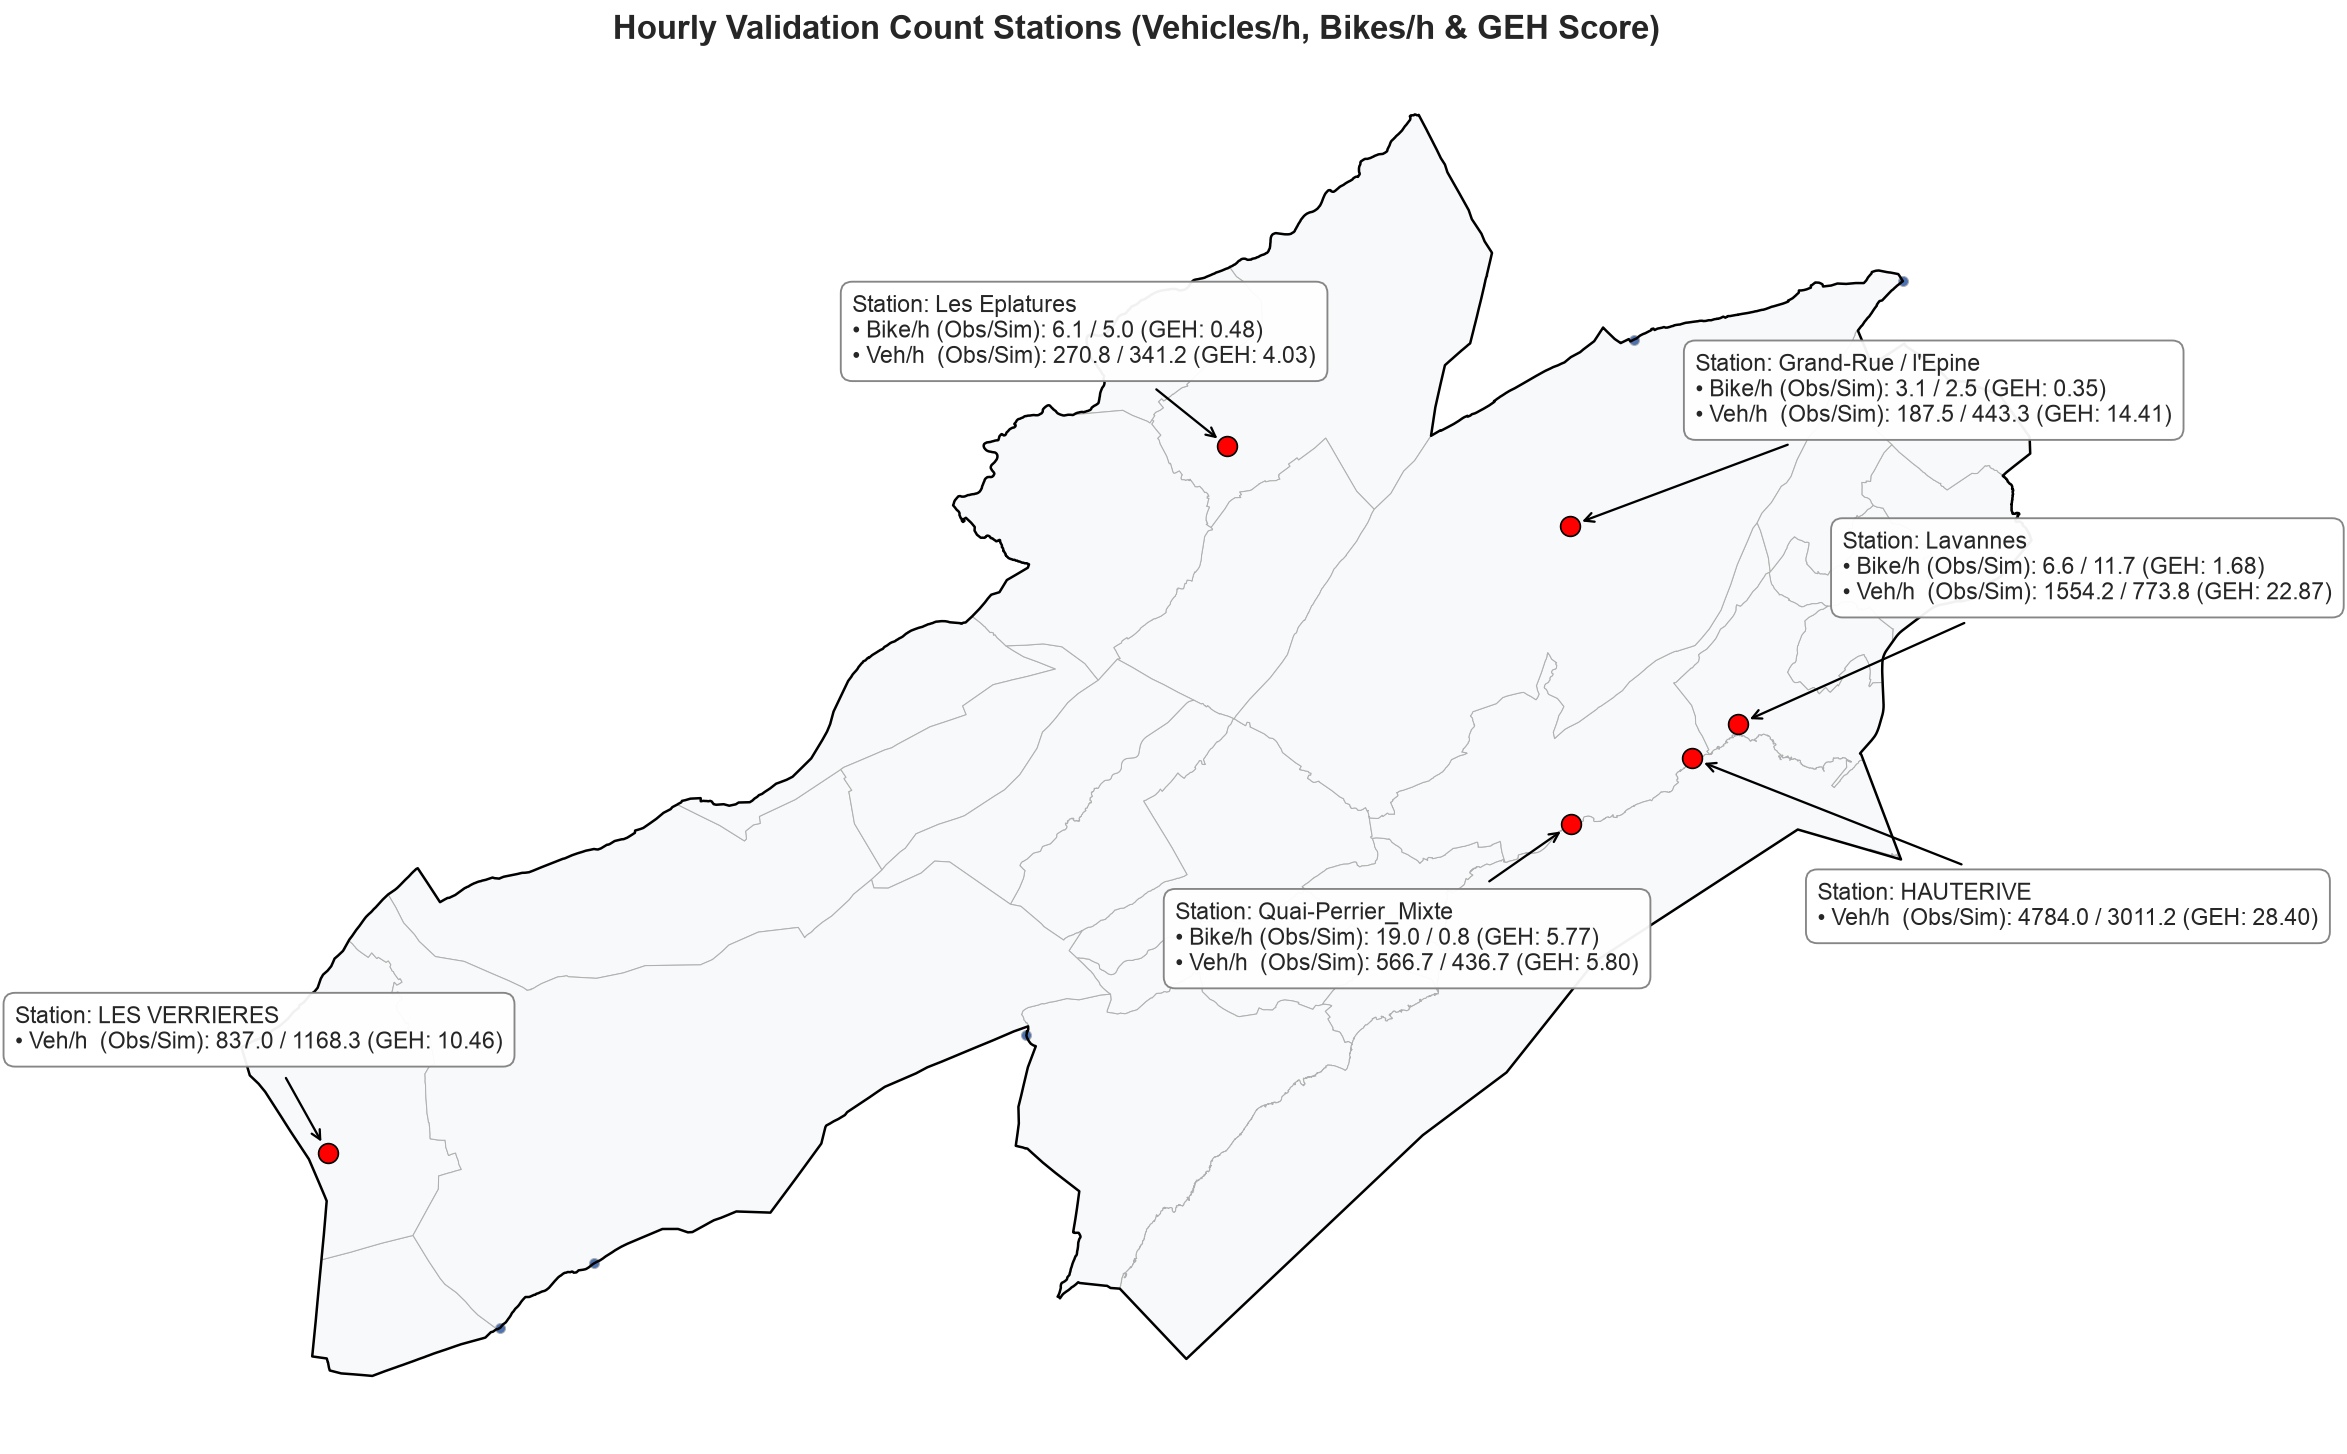

In [498]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. GEH-beregningsfunksjon (på timebasis)
def calculate_geh(simulated: pd.Series, observed: pd.Series) -> pd.Series:
    geh = np.where(
        (observed >= 0) & ((simulated + observed) > 0),
        np.sqrt(2 * ((simulated - observed) ** 2) / (simulated + observed)),
        np.nan
    )
    return pd.Series(geh, index=observed.index)

# 2. Tellestasjoner
# Tall som allerede er timeverdier (f.eks. 837 og 4784) skrives direkte uten /24
count_stations_data = [
    {"station_name": "Quai-Perrier_Mixte", "count_bikes": 456/24, "coords_ch1903": "2560490 1204220", "link_id": ["10444633", "2940181"], "count_aadt": 13600/24},
    {"station_name": "Lavannes",           "count_bikes": 158/24, "coords_ch1903": "2565158 1207012", "link_id": ["126984", "1456192"], "count_aadt": 37300/24},
    {"station_name": "Grand-Rue / l'Epine", "count_bikes": 74/24,  "coords_ch1903": "2560470 1212547", "link_id": ["1104888","1104888"], "count_aadt": 4500/24},
    {"station_name": "Les Eplatures",      "count_bikes": 147/24, "coords_ch1903": "2550897 1214769", "link_id": ["2254710", "1590951"], "count_aadt": 6500/24},
    {"station_name": "LES VERRIERES",      "count_bikes": -1,     "coords_ch1903": "2525793 1195061", "link_id": ["763850", "763851"],   "count_aadt": 837},
    {"station_name": "HAUTERIVE",          "count_bikes": -1,     "coords_ch1903": "2563876 1206061", "link_id": ["89300", "962191"],    "count_aadt": 4784}
]

df_stations = pd.DataFrame(count_stations_data)
coords_xy = df_stations['coords_ch1903'].str.split(' ', expand=True).astype(float)

# Opprett GeoDataFrame for stasjonene
gdf_validation = gpd.GeoDataFrame(
    df_stations.drop(columns=['coords_ch1903']),
    geometry=gpd.points_from_xy(coords_xy[0], coords_xy[1]),
    crs=2056
)

# 3. Les simuleringsdata
SAMPLE_SCALE_FACTOR = 10
sim_stats_filepath = "Neuchatel_10pct/simulation_output/output_detailed_link_statistics.csv.gz"
df_sim_links = pd.read_csv(sim_stats_filepath, compression='gzip')

# Konverter link_id til streng
df_sim_links['link_id'] = df_sim_links['link_id'].astype(str)

# Hent alle unike link_id-er fra stasjonslisten
all_target_link_ids = set([link for sublist in gdf_validation['link_id'] for link in sublist])

# Filtrer ut relevante lenker fra simuleringsdataene
df_matched = df_sim_links[df_sim_links['link_id'].isin(all_target_link_ids)].copy()

MOTORIZED_MODES = ['cars', 'trucks', 'buses', 'cars_french', 'cars_crossborder', 'cars_swiss', 'cars_unknown']

# Summer per enveis-lenke over alle 24 timer
agg_dict = {'bikes': 'sum', **{mode: 'sum' for mode in MOTORIZED_MODES}}
df_link_summary = df_matched.groupby('link_id').agg(agg_dict).reset_index()

# Skaler opp med sampelfaktor for å få totalt døgnvolum per lenke
df_link_summary['sim_aadt_24h_link'] = df_link_summary[MOTORIZED_MODES].sum(axis=1) * SAMPLE_SCALE_FACTOR
df_link_summary['sim_bikes_24h_link'] = df_link_summary['bikes'] * SAMPLE_SCALE_FACTOR

# 4. Kople enveis-lenkene til stasjonene og summer begge retninger
gdf_exploded = gdf_validation.explode('link_id')

gdf_merged_links = gdf_exploded.merge(
    df_link_summary[['link_id', 'sim_bikes_24h_link', 'sim_aadt_24h_link']], 
    on='link_id', 
    how='left'
).fillna({'sim_bikes_24h_link': 0, 'sim_aadt_24h_link': 0})

# Grupper per stasjon for å få toveis sum for hele døgnet
df_station_sim = gdf_merged_links.groupby('station_name').agg({
    'sim_bikes_24h_link': 'sum',
    'sim_aadt_24h_link': 'sum'
}).reset_index()

# Del på 24 for å få gjennomsnittlig timevolum for simuleringen
df_station_sim['sim_bikes'] = df_station_sim['sim_bikes_24h_link'] / 24.0
df_station_sim['sim_aadt'] = df_station_sim['sim_aadt_24h_link'] / 24.0

# Merge de timelige simuleringsverdiene tilbake til stasjons-GeoDataFrame-en
gdf_validation = gdf_validation.merge(
    df_station_sim[['station_name', 'sim_bikes', 'sim_aadt']], 
    on='station_name', 
    how='left'
)

# 5. Beregn GEH på timebasis
gdf_validation['geh_aadt'] = calculate_geh(gdf_validation['sim_aadt'], gdf_validation['count_aadt'])
gdf_validation['geh_bikes'] = calculate_geh(gdf_validation['sim_bikes'], gdf_validation['count_bikes'])

# 6. Visualisering
fig, ax = plt.subplots(figsize=(16, 12))

# Bakgrunnskart
areas.plot(ax=ax, facecolor='#f8f9fa', edgecolor='#b0b0b0', linewidth=0.5, zorder=1)
boundary.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=1.2, zorder=2)

# Tellestasjoner (tegnes helt øverst med zorder=10)
gdf_validation.plot(ax=ax, marker='o', color='red', markersize=90, edgecolor='black', zorder=10)

# Spesifikke forskyvninger (x, y i punkter) for å spre boksene ut i ledig areal rundt kulene
MANUAL_OFFSETS = {
    "Quai-Perrier_Mixte": (-190, -70),  # Flyttes langt ned til venstre (ut i sjøen/åpent rom)
    "HAUTERIVE":          (60, -80),    # Flyttes ned til høyre
    "Lavannes":           (50, 60),     # Flyttes opp til høyre
    "Grand-Rue / l'Epine":(60, 50),    # Flyttes ned til høyre
    "Les Eplatures":      (-180, 40),   # Flyttes opp til venstre
    "LES VERRIERES":      (-150, 50)    # Flyttes opp til venstre
}

for idx, row in gdf_validation.iterrows():
    has_bike_data = row['count_bikes'] >= 0
    
    label_lines = [f"Station: {row['station_name']}"]
    if has_bike_data:
        label_lines.append(
            f"• Bike/h (Obs/Sim): {row['count_bikes']:.1f} / {row['sim_bikes']:.1f} (GEH: {row['geh_bikes']:.2f})"
        )
    label_lines.append(
        f"• Veh/h  (Obs/Sim): {row['count_aadt']:.1f} / {row['sim_aadt']:.1f} (GEH: {row['geh_aadt']:.2f})"
    )
    label_text = "\n".join(label_lines)

    # Hent manuell forskyvning
    offset = MANUAL_OFFSETS.get(row['station_name'], (40, 40))

    ax.annotate(
        label_text,
        xy=(row.geometry.x, row.geometry.y),
        xytext=offset,
        textcoords="offset points",
        fontsize=11,
        bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray", lw=0.9, alpha=0.95),
        arrowprops=dict(
            arrowstyle="->", 
            connectionstyle="arc3,rad=0", 
            color="black", 
            lw=1.1,
            shrinkA=6,  # Sørger for at pilen stopper rett utenfor boks/kule
            shrinkB=6
        ),
        zorder=5
    )

ax.set_title("Hourly Validation Count Stations (Vehicles/h, Bikes/h & GEH Score)", fontsize=16, fontweight='bold')
ax.axis('off')

plt.tight_layout()
plt.show()

173	LES VERRIERES			NE	H 10	837	TUE / 16	06		301	06	10		204	14	11
Geo_Nord_LV95	1 195 061
Geo_Ost_LV95	2 525 793

676	HAUTERIVE (AR)			NE	A 5	4784	TUE / 02	17		3 306	27	11		2 567	21	17
Geo_Nord_LV95	1 206 061
Geo_Ost_LV95	2 563 876

In [491]:
def find_closest_links_to_counters():
    """
    This function processes bike counter data and finds the 10 closest links from a network XML file for each counter.
    It then prepares the data for visualization on a map.
    """
    import gzip
    import xml.etree.ElementTree as ET
    import geopandas as gpd
    import pandas as pd
    import plotly.express as px
    from shapely.geometry import LineString
    import plotly.graph_objects as go
    import nbformat

    # 1. Definer sykkeltellerdataene (EPSG:2056)
    ghs_data = [
        ["name", "count", "CH1903+"],
        ["Quai-Perrier_Mixte", 456, "2560490 1204220"],
        ["Lavannes", 158, "2565158 1207012"],
        ["Grand-Rue / l'Epine", 74, "2560470 1212547"],
        ["Les Eplatures", 147, "2550897 1214769"],
        ["LES VERRIERES", 837, "2525793 1195061"],
        ["HAUTERIVE", 4784, "2563876 1206061"]
    ]

    gdf_counters = gpd.GeoDataFrame(
        ghs_data[1:], 
        columns=ghs_data[0], 
        geometry=gpd.points_from_xy(
            [float(row[2].split()[0]) for row in ghs_data[1:]], 
            [float(row[2].split()[1]) for row in ghs_data[1:]]
        ), 
        crs=2056
    )

    # 2. Parse XML-nettverksfilen (filtrer ut rene PT-lenker)
    xml_file_path = "Neuchatel_10pct/neuchatel_network.xml.gz"
    nodes = {}
    links = []

    # Tillatte moduser
    ALLOWED_MODES = {"car", "bike", "bicycle", "ride", "walk"}

    with gzip.open(xml_file_path, 'rt', encoding='utf-8') as f:
        tree = ET.parse(f)
        root = tree.getroot()

        for node in root.findall(".//node"):
            nodes[node.get("id")] = (float(node.get("x")), float(node.get("y")))

        for link in root.findall(".//link"):
            link_id = link.get("id")
            from_node = link.get("from")
            to_node = link.get("to")
            modes_attr = link.get("modes", "")
            
            # Hopp over eksplisitte kollektivtransport-lenker om de mangler veimodus
            if link_id.startswith("pt_"):
                continue
                
            link_modes = set(modes_attr.replace(',', ' ').split())
            if link_modes and not link_modes.intersection(ALLOWED_MODES):
                continue

            if from_node in nodes and to_node in nodes:
                geom = LineString([nodes[from_node], nodes[to_node]])
                links.append({
                    "link_id": link_id,
                    "from_node": from_node,
                    "to_node": to_node,
                    "modes": modes_attr,
                    "geometry": geom
                })

    gdf_links = gpd.GeoDataFrame(links, crs=2056)

    # 3. Finn de 10 nærmeste lenkene per teller
    results = []
    K = 10  # Antall nærmeste lenker du vil hente ut

    for idx, counter in gdf_counters.iterrows():
        temp_links = gdf_links.copy()
        temp_links["distance_m"] = temp_links.geometry.distance(counter.geometry)
        temp_links["name"] = counter["name"]
        
        top_k = temp_links.nsmallest(K, "distance_m").copy()
        top_k["rank"] = range(1, K + 1)
        results.append(top_k)

    top10_links = pd.concat(results, ignore_index=True)
    top10_links = gpd.GeoDataFrame(top10_links, crs=2056)

    # Sorter og legg til en rangering (1-10) for hver teller
    top10_links["rank"] = top10_links.groupby("name")["distance_m"].rank(method="first").astype(int)

    # Skriv ut tabell i konsollen
    print(top10_links[["name", "rank", "link_id", "modes", "distance_m"]])

    # 4. Forbered geodata for kartvisning (Konverter til EPSG:4326 for bakgrunnskart)
    gdf_counters_wgs = gdf_counters.to_crs(epsg=4326)
    top10_links_wgs = top10_links.to_crs(epsg=4326)

    fig = go.Figure()

    # Legg til de 10 nærmeste lenkene for hver teller
    for idx, row in top10_links_wgs.iterrows():
        lons, lats = row.geometry.xy
        
        hover_text = (
            f"Teller: {row['name']}<br>"
            f"Rangering: #{row['rank']}<br>"
            f"Link ID: {row['link_id']}<br>"
            f"Avstand: {row['distance_m']:.1f} m<br>"
            f"Moduser: {row['modes']}"
        )
        
        fig.add_trace(go.Scattermap(
            lon=list(lons),
            lat=list(lats),
            mode='lines',
            line=dict(width=4),
            name=f"#{row['rank']} {row['link_id']} ({row['name']})",
            text=hover_text,
            hoverinfo='text'
        ))

    # Legg til tellerpunktene (Røde stjerner/markører)
    fig.add_trace(go.Scattermap(
        lon=gdf_counters_wgs.geometry.x,
        lat=gdf_counters_wgs.geometry.y,
        mode='markers+text',
        marker=dict(size=14, color='red'),
        text=gdf_counters_wgs['name'],
        textposition="top center",
        name="Sykkeltellere",
        hoverinfo='text'
    ))

    # Sett kartets senter og zoom ut fra tellerpunktene
    center_lat = gdf_counters_wgs.geometry.y.mean()
    center_lon = gdf_counters_wgs.geometry.x.mean()

    fig.update_layout(
        map=dict(
            style="open-street-map",
            center=dict(lat=center_lat, lon=center_lon),
            zoom=11
        ),
        height=750,
        title="Top 10 nærmeste veilenker for hver sykkelteller",
        margin=dict(l=10, r=10, t=40, b=10)
    )

    #fig.show(renderer="browser")

                   name  rank  link_id                                  modes  \
0    Quai-Perrier_Mixte     1   282711      bike,car,car_passenger,taxi,truck   
1    Quai-Perrier_Mixte     2   781676  bike,bus,car,car_passenger,taxi,truck   
2    Quai-Perrier_Mixte     3  1044633  bike,bus,car,car_passenger,taxi,truck   
3    Quai-Perrier_Mixte     4  2940181  bike,bus,car,car_passenger,taxi,truck   
4    Quai-Perrier_Mixte     5    10697  bike,bus,car,car_passenger,taxi,truck   
5    Quai-Perrier_Mixte     6    10698  bike,bus,car,car_passenger,taxi,truck   
6    Quai-Perrier_Mixte     7  2864737      bike,car,car_passenger,taxi,truck   
7    Quai-Perrier_Mixte     8  2864738      bike,car,car_passenger,taxi,truck   
8    Quai-Perrier_Mixte     9    10696  bike,bus,car,car_passenger,taxi,truck   
9    Quai-Perrier_Mixte    10   623648  bike,bus,car,car_passenger,taxi,truck   
10             Lavannes     1  1977807  bike,bus,car,car_passenger,taxi,truck   
11             Lavannes     